# 이커머스 데이터 분석 리포트: 단골 고객 찾기

이 노트북은 두 데이터로 분석한다.

| 데이터 | 역할 | 출처·라이선스 |
|---|---|---|
| 거래 데이터 `online_retail_II.csv` | 고객 구매 분석, RFM 세분화 | [UCI Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii), Chen, D. (2012), CC BY 4.0 |
| 상품 데이터 `products.csv` + 상품 이미지 | 멀티 모달(텍스트·범주·이미지) 피처 엔지니어링 | [Fashion Product Images (Small)](https://www.kaggle.com/datasets/paramaggarwal/fashion-product-images-small), MIT. Hugging Face 미러 `ashraq/fashion-product-images-small`에서 2,000개 표본 |

두 데이터는 서로 다른 회사의 데이터라 상품이 연결되지 않는다. 그래서 **고객 거래 분석**과 **상품 멀티 모달 분석**을 두 흐름으로 나눠 진행한다.

분석 로직은 모두 `src/pipeline.py`의 `DataAnalyzer` 클래스에 있고, 이 노트북은 그 메서드를 호출하며 결과를 해석한다. 데이터 준비: `uv run python scripts/download_data.py`

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from pipeline import DataAnalyzer
from plot_style import BLUE, GRAY, GREEN, ORANGE, RED, SEGMENT_COLORS, plain_log_ticks, save_figure, setup_style

np.random.seed(42)
setup_style()
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. 데이터 로드와 기본 탐색

### 1-1. 거래 데이터

In [2]:
tx = DataAnalyzer(ROOT / "data" / "online_retail_II.csv")
tx.load_data(parse_dates=["InvoiceDate"],
             dtype={"Invoice": str, "StockCode": str, "Customer ID": "string"})
tx.df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  str           
 1   StockCode    1067371 non-null  str           
 2   Description  1062989 non-null  str           
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   string        
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), str(4), string(1)
memory usage: 65.1 MB


In [3]:
tx.df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom


In [4]:
tx.df.describe()

,Quantity,InvoiceDate,Price
count,"1,067,371.00",1067371,"1,067,371.00"
mean,9.94,2011-01-02 21:13:55.394029,4.65
min,"-80,995.00",2009-12-01 07:45:00,"-53,594.36"
25%,1.00,2010-07-09 09:46:00,1.25
50%,3.00,2010-12-07 15:28:00,2.10
75%,10.00,2011-07-22 10:23:00,4.15
max,"80,995.00",2011-12-09 12:50:00,"38,970.00"
std,172.71,NaN,123.55


In [5]:
d = tx.df
print(f"기간: {d['InvoiceDate'].min()} ~ {d['InvoiceDate'].max()}")
print(f"주문 수: {d['Invoice'].nunique():,}, 상품 코드 수: {d['StockCode'].nunique():,}, "
      f"고객 수: {d['Customer ID'].nunique():,}, 국가 수: {d['Country'].nunique()}")
print(f"취소 주문 행(Invoice가 C로 시작): {d['Invoice'].str.startswith('C').sum():,}")
print(f"수량 0 이하: {(d['Quantity'] <= 0).sum():,}, 단가 0 이하: {(d['Price'] <= 0).sum():,}")
print(f"영국 비중: {(d['Country'] == 'United Kingdom').mean() * 100:.1f}%")

기간: 2009-12-01 07:45:00 ~ 2011-12-09 12:50:00


주문 수: 53,628, 상품 코드 수: 5,305, 고객 수: 5,942, 국가 수: 43
취소 주문 행(Invoice가 C로 시작): 19,494
수량 0 이하: 22,950, 단가 0 이하: 6,207
영국 비중: 91.9%


**해석**

- 거래 데이터는 1,067,371행 × 8열이고, 2009-12-01부터 2011-12-09까지 약 2년 동안의 주문 53,628건이다. 고객 5,942명, 상품 코드 5,305개, 43개국이 있지만 **영국 비중이 91.9%**로 사실상 영국 쇼핑몰이다.
- `Quantity`의 최솟값 −80,995와 최댓값 80,995가 같은 크기다. 큰 주문이 들어왔다가 그대로 취소된 흔적이다. 취소 주문 행이 19,494개, 수량 0 이하 22,950개, 단가 0 이하 6,207개라서 **판매 분석 전에 이런 행을 걸러야 한다.**
- `Quantity` 평균 9.94가 중앙값 3의 3배가 넘는다. 소수의 대량 주문이 평균을 끌어올리는 **오른쪽으로 긴 분포**이므로, 대표값은 중앙값으로 보고 그래프는 로그 축으로 그린다.

### 1-2. 상품 데이터 (멀티 모달)

In [6]:
pr = DataAnalyzer(ROOT / "data" / "products.csv")
pr.load_data()
pr.df["image_path"] = [str(ROOT / p) for p in pr.df["image_path"]]
pr.df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  2000 non-null   int64  
 1   gender              2000 non-null   str    
 2   masterCategory      2000 non-null   str    
 3   subCategory         2000 non-null   str    
 4   articleType         2000 non-null   str    
 5   baseColour          2000 non-null   str    
 6   season              2000 non-null   str    
 7   year                2000 non-null   float64
 8   usage               2000 non-null   str    
 9   productDisplayName  2000 non-null   str    
 10  image_path          2000 non-null   str    
dtypes: float64(1), int64(1), str(9)
memory usage: 172.0 KB


In [7]:
pr.df.head()

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,image_path
0,35542,Girls,Footwear,Sandal,Sandals,Pink,Summer,"2,012.00",Casual,Enroute Kids Girls Pink Sandals,/Users/ashofrondol/Desktop/temp/codyssey_A1-1/...
1,26969,Women,Apparel,Topwear,Tops,White,Summer,"2,012.00",Casual,Jealous 21 Women Printed White & Blue Top,/Users/ashofrondol/Desktop/temp/codyssey_A1-1/...
2,51007,Women,Apparel,Innerwear,Bra,Black,Summer,"2,017.00",Casual,Enamor Black Full Figure Bra,/Users/ashofrondol/Desktop/temp/codyssey_A1-1/...
3,48916,Women,Accessories,Jewellery,Pendant,Silver,Summer,"2,013.00",Casual,Lucera Women Silver Pendant,/Users/ashofrondol/Desktop/temp/codyssey_A1-1/...
4,17612,Girls,Apparel,Topwear,Tshirts,Grey,Fall,"2,011.00",Casual,Doodle Cute Girls Grey Tshirt,/Users/ashofrondol/Desktop/temp/codyssey_A1-1/...


In [8]:
pr.df.describe(include="all").T[["count", "unique", "top", "freq", "mean", "min", "max"]]

,count,unique,top,freq,mean,min,max
id,"2,000.00",NaN,NaN,NaN,"29,701.46","1,164.00","59,979.00"
gender,2000,5,Men,984,NaN,NaN,NaN
masterCategory,2000,5,Apparel,1000,NaN,NaN,NaN
subCategory,2000,32,Topwear,715,NaN,NaN,NaN
articleType,2000,93,Tshirts,317,NaN,NaN,NaN
baseColour,2000,41,Black,435,NaN,NaN,NaN
season,2000,4,Summer,970,NaN,NaN,NaN
year,"2,000.00",NaN,NaN,NaN,"2,012.71","2,010.00","2,018.00"
usage,2000,6,Casual,1534,NaN,NaN,NaN
productDisplayName,2000,1904,Lucera Women Silver Earrings,5,NaN,NaN,NaN


In [9]:
types = pd.DataFrame({
    "데이터": ["거래", "거래", "거래", "거래", "상품", "상품", "상품", "상품"],
    "유형": ["수치형", "범주형", "날짜형", "텍스트", "수치형", "범주형", "텍스트", "이미지(배열)"],
    "컬럼": ["Quantity, Price", "Country, StockCode", "InvoiceDate", "Description",
             "year (+ 이미지 피처)", "gender, masterCategory, articleType, baseColour, season, usage",
             "productDisplayName", "image_path → (80, 60) 배열"],
})
types

,데이터,유형,컬럼
0,거래,수치형,"Quantity, Price"
1,거래,범주형,"Country, StockCode"
2,거래,날짜형,InvoiceDate
3,거래,텍스트,Description
4,상품,수치형,year (+ 이미지 피처)
5,상품,범주형,"gender, masterCategory, articleType, baseColou..."
6,상품,텍스트,productDisplayName
7,상품,이미지(배열),"image_path → (80, 60) 배열"


**해석**

- 상품 표본은 2,000개 × 11열(이미지 경로 포함)이고 수치형(`year`), 범주형 6개, 텍스트(`productDisplayName`), 이미지까지 **4가지 유형**이 모두 있다. 거래 데이터까지 합치면 날짜형도 있어 명세의 "3가지 이상"을 채운다.
- 카테고리가 고르지 않다. Apparel이 1,000개(50%)로 절반이고 Free Items는 4개뿐이다. 상품 종류(`articleType`)는 93종이며 Tshirts가 317개로 가장 많다.
- 그래서 이미지 피처를 비교할 때는 **카테고리별로 나눠 보아야** 표본이 많은 의류의 특성이 전체 결과를 덮지 않는다.

## 2. 전처리 기준: 무엇을 빼고 무엇을 남기나

"이상한 값"은 두 종류로 나눠 다룬다.

| 종류 | 뜻 | 예 | 처리 |
|---|---|---|---|
| **규칙 위반** | 데이터의 뜻으로 볼 때 판매 기록이 될 수 없는 행 | 완전 중복, 배송비·수수료 같은 비상품 코드, 취소 주문, 단가 0 이하 | 근거를 남기고 **빼거나 따로 다룬다** |
| **통계적 이상치** | 있을 수 있지만 드문 값 | 대량 도매 주문 | **정체를 확인한 뒤** 판단한다 (5장) |

규칙 위반을 먼저 정리해야 통계적 이상치의 기준(Q1, Q3)이 규칙 위반 행에 오염되지 않는다. 여기서는 모든 분석에 공통으로 적용할 두 가지를 먼저 처리한다.

### 2-1. 완전 중복 행

In [10]:
dup_mask = tx.df.duplicated(keep=False)
print(f"모든 열이 같은 행이 있는 묶음의 행 수: {dup_mask.sum():,}")
print(f"그중 지울 행 (첫 행만 남김): {tx.df.duplicated().sum():,}")
example = tx.df[dup_mask].sort_values(["Invoice", "StockCode"]).head(4)
example

모든 열이 같은 행이 있는 묶음의 행 수: 67,242


그중 지울 행 (첫 행만 남김): 34,335


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom


In [11]:
n_dup = tx.remove_duplicates()
print(tx.log[-1])

remove_duplicates: 34,335행 삭제


### 2-2. 상품이 아닌 코드

In [12]:
from pipeline import NON_PRODUCT_CODES, NON_PRODUCT_PREFIXES

removed = tx.exclude_codes("StockCode")
removed["amount"] = removed["Quantity"] * removed["Price"]
summary = (removed.groupby("reason")
           .agg(행수=("StockCode", "size"), 코드=("StockCode", lambda s: ", ".join(sorted(s.unique())[:4])),
                금액합=("amount", "sum"))
           .sort_values("행수", ascending=False))
print(tx.log[-1])
summary

exclude_codes(StockCode): 5,801행 제외 (코드 26종)


,행수,코드,금액합
reason,,,
우편료,2086,POST,"110,430.41"
온라인 주문 우편료,1425,DOT,"309,844.10"
수동 입력(Manual),1392,"M, m","-83,311.28"
운송비,278,"C2, C3","13,136.00"
할인,173,D,"-12,879.63"
샘플,101,S,"-5,991.11"
상품권,101,"GIFT, gift_0001_10, gift_0001_20, gift_0001_30","1,686.61"
은행 수수료,100,BANK CHARGES,"-35,482.25"
회계 조정,70,"ADJUST, ADJUST2","7,566.29"


In [13]:
left_codes = tx.df.loc[~tx.df["StockCode"].str.match(r"^\d{5}"), "StockCode"].unique()
print(f"숫자 5자리로 시작하지 않지만 남긴 코드 {len(left_codes)}종 (실제 상품):", sorted(left_codes)[:8], "...")

숫자 5자리로 시작하지 않지만 남긴 코드 36종 (실제 상품): ['DCGS0003', 'DCGS0004', 'DCGS0006', 'DCGS0016', 'DCGS0027', 'DCGS0036', 'DCGS0037', 'DCGS0039'] ...


In [14]:
# 판매로 보지 않을 나머지 규칙 위반 (중복·비상품 코드를 정리한 뒤 기준)
d = tx.df
print(f"취소 주문 행 (Invoice가 C로 시작): {d['Invoice'].str.startswith('C').sum():,}")
print(f"취소가 아닌데 수량 0 이하: {((d['Quantity'] <= 0) & ~d['Invoice'].str.startswith('C')).sum():,}")
print(f"단가 0 이하: {(d['Price'] <= 0).sum():,}")
print(f"남은 행: {len(d):,}")

취소 주문 행 (Invoice가 C로 시작): 17,915


취소가 아닌데 수량 0 이하: 3,391
단가 0 이하: 5,963
남은 행: 1,027,235


**해석**

- **완전 중복 34,335행**: 모든 열이 같은 행이다. 그중 22,844행(67%)이 2010년 12월 1~9일에 몰려 있다. 원본 엑셀이 2009~2010년, 2010~2011년 두 시트로 나뉘어 있는데, **두 시트가 이 기간을 겹쳐서 담고 있었다.** 지우지 않으면 2010년 12월 초 매출이 두 번 세어진다(중복만 지워도 2010년 12월 매출이 126만에서 82만 파운드로 줄어든다). 나머지 약 1만 1천 행은 같은 주문 안에 같은 상품 줄이 반복된 것이다. 주문 번호·시각·수량·가격까지 모두 같아 실제로 두 번 산 것과 입력 반복을 구분할 근거가 없으므로, 보수적으로 하나만 남겼다.
- **상품이 아닌 코드 5,801행(26종)**: 우편료(`POST`, `DOT`), 운송비, 수동 입력(`M`), 할인, 샘플, 상품권, 은행·아마존·자선단체 수수료, 회계 조정, 악성 채권 조정, 테스트 상품이다. 상품 판매가 아니므로 상품 분석과 고객 구매 금액(RFM)에서 뺐다. 기준은 "상품 코드는 숫자 5자리로 시작한다"이고, 숫자로 시작하지 않아도 실제 상품인 `DCGS…`(반려동물·파티 용품), `PADS`, `SP1002`는 남겼다. 뺀 코드 목록과 이유는 `src/pipeline.py`의 `NON_PRODUCT_CODES`에 적어 두었다.
- 정리 후 남은 거래는 1,027,235행이다. 이 중 취소 주문 17,915행과 단가 0 이하 5,963행은 3-1절에서 판매 분석용 데이터를 만들 때 따로 다룬다(취소는 RFM 순 구매 금액 계산에 쓴다).
- 시사점: 규칙 위반은 개수는 적어도 결과를 크게 바꿀 수 있다. 중복 때문에 2010년 12월 매출이 50% 넘게 부풀어 있었다.

## 3. 결측치 처리

In [15]:
tx.missing_report()

,결측 개수,결측 비율(%)
Invoice,0,0.00
StockCode,0,0.00
Description,4239,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,232991,22.68
Country,0,0.00


In [16]:
pr.missing_report().T

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,image_path
결측 개수,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
결측 비율(%),0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [17]:
# 같은 상품 코드(StockCode)는 같은 상품명을 가지므로, 코드별 최빈 상품명으로 채운다 (그룹별 대치)
missing_desc = tx.df["Description"].isna()
filled = tx.handle_missing_values("Description", strategy="group_mode", group_col="StockCode")
left = int(tx.df["Description"].isna().sum())
print(f"Description 결측 {missing_desc.sum():,}칸 중 {filled:,}칸을 같은 StockCode의 최빈 상품명으로 채움")
print(f"남은 {left:,}칸은 그 StockCode에 상품명이 한 번도 없어 'UNKNOWN'으로 채움")
tx.handle_missing_values("Description", strategy="constant", fill_value="UNKNOWN")
print("남은 결측 행의 단가 분포 (대부분 0원):")
print(tx.df.loc[missing_desc, "Price"].describe())

Description 결측 4,239칸 중 3,882칸을 같은 StockCode의 최빈 상품명으로 채움
남은 357칸은 그 StockCode에 상품명이 한 번도 없어 'UNKNOWN'으로 채움
남은 결측 행의 단가 분포 (대부분 0원):
count   4,239.00
mean        0.00
std         0.00
min         0.00
25%         0.00
50%         0.00
75%         0.00
max         0.00
Name: Price, dtype: float64


In [18]:
# Customer ID는 추정할 근거가 없어 채우지 않는다. RFM에서는 제외하고, 매출 분석에는 포함한다.
no_id = tx.df["Customer ID"].isna()
print(f"Customer ID 결측: {no_id.sum():,}행 ({no_id.mean() * 100:.1f}%)")
print(f"결측 행의 매출 비중: {(tx.df.loc[no_id, 'Quantity'] * tx.df.loc[no_id, 'Price']).sum() / (tx.df['Quantity'] * tx.df['Price']).sum() * 100:.1f}%")

Customer ID 결측: 232,991행 (22.7%)
결측 행의 매출 비중: 13.6%


**해석**

- `Description`(상품명) 결측은 4,239칸(0.41%)이고, **이 행들의 단가는 모두 0**이다. 실제 판매가 아니라 재고 조정 같은 내부 기록으로 보인다. 같은 `StockCode`의 최빈 상품명으로 3,882칸을 채웠고(그룹별 대치), 남은 357칸은 그 코드에 상품명이 한 번도 없어 `UNKNOWN`으로 채웠다. 어차피 단가 0인 행이라 판매 분석에서는 빠진다.
- `Customer ID` 결측은 232,991행(22.7%)이고 매출의 13.6%를 차지한다. 고객 번호는 다른 값으로 추정할 근거가 없으므로 **채우지 않고 RFM에서만 제외**했다. 월별 매출 같은 전체 매출 분석에는 포함한다.
- 시사점: RFM 결과는 고객 번호가 있는 매출(약 86%)만 반영한다. 비회원 구매가 이 정도라면, 구매 시 회원 가입이나 이메일 수집을 유도해야 고객 분석 범위가 넓어진다.
- 상품 데이터는 결측치가 없다(미러 데이터가 결측 행을 정리한 상태로 보인다).

### 3-1. 분석용 판매 데이터 만들기

취소 주문, 수량 0 이하, 단가 0 이하 행은 실제 판매가 아니므로 판매 분석에서 뺀다. 금액은 `amount = Quantity × Price`로 만든다.

In [19]:
raw = tx.df
is_cancel = raw["Invoice"].str.startswith("C")
valid = ~is_cancel & (raw["Quantity"] > 0) & (raw["Price"] > 0)
sales = raw[valid].copy()
sales["amount"] = sales["Quantity"] * sales["Price"]
print(f"전체 {len(raw):,}행 → 판매 {len(sales):,}행 (취소 {is_cancel.sum():,}, 그 밖에 제외 {(~valid & ~is_cancel).sum():,})")
sa = DataAnalyzer(df=sales)

# RFM용: 고객 ID가 있고 단가가 0보다 큰 행. 취소 행(음수 금액)도 남겨 순 구매 금액을 계산한다.
rfm_base = raw[raw["Customer ID"].notna() & (raw["Price"] > 0) & (raw["Quantity"] != 0)].copy()
rfm_base["amount"] = rfm_base["Quantity"] * rfm_base["Price"]
cancel_amt = rfm_base.loc[rfm_base["Invoice"].str.startswith("C"), "amount"].sum()
buy_amt = rfm_base.loc[~rfm_base["Invoice"].str.startswith("C"), "amount"].sum()
print(f"고객 ID가 있는 구매 {buy_amt:,.0f}파운드 중 취소 {-cancel_amt:,.0f}파운드 ({-cancel_amt / buy_amt * 100:.1f}%)")

전체 1,027,235행 → 판매 1,003,357행 (취소 17,915, 그 밖에 제외 5,963)


고객 ID가 있는 구매 17,068,583파운드 중 취소 709,990파운드 (4.2%)


### 3-2. 그룹별 대치가 통계량에 주는 영향

그룹별 대치는 편하지만 대가가 있다. 채운 값은 진짜 값이 아니라 **그룹의 대표값**이라서, 분포가 실제보다 덜 퍼져 보일 수 있다. 얼마나 달라지는지 숫자로 확인한다.

**실험 방법**: 판매 데이터의 `Price`는 결측이 없다. 그래서 일부러 10%를 무작위로 지우고(seed 42), 두 방법으로 채운 뒤 원래 값과 비교한다.

- 전체 중앙값 대치: 모든 빈칸을 같은 숫자 하나로 채운다.
- 그룹 중앙값 대치: 같은 `StockCode`의 중앙값으로 채운다 (`handle_missing_values(strategy="group_median")`).

In [20]:
rng = np.random.default_rng(42)
exp = DataAnalyzer(df=sales[["StockCode", "Price"]].copy())
truth = exp.df["Price"].copy()
hide = rng.random(len(truth)) < 0.10
exp.df.loc[hide, "Price"] = np.nan

a_all = DataAnalyzer(df=exp.df.copy()); a_all.handle_missing_values("Price", strategy="median")
a_grp = DataAnalyzer(df=exp.df.copy()); a_grp.handle_missing_values("Price", strategy="group_median", group_col="StockCode")

def describe_fill(name, price):
    by = price.groupby(exp.df["StockCode"])
    return {"방법": name,
            "전체 표준편차": price.std(),
            "그룹 안 표준편차 (중앙값)": by.std().median(),
            "그룹 평균끼리의 표준편차": by.mean().std(),
            "채운 칸의 평균 오차": np.nan if price is truth else (price[hide] - truth[hide]).abs().mean(),
            "남은 결측": int(price.isna().sum())}

imp_table = pd.DataFrame([describe_fill("원래 값 (지우기 전)", truth),
                          describe_fill("전체 중앙값 대치", a_all.df["Price"]),
                          describe_fill("그룹 중앙값 대치", a_grp.df["Price"])]).set_index("방법")
print(f"지운 칸: {hide.sum():,}개 ({hide.mean() * 100:.1f}%)")
imp_table

지운 칸: 100,018개 (10.0%)


,전체 표준편차,그룹 안 표준편차 (중앙값),그룹 평균끼리의 표준편차,채운 칸의 평균 오차,남은 결측
방법,,,,,
원래 값 (지우기 전),4.75,0.69,7.99,NaN,0
전체 중앙값 대치,4.55,0.79,7.13,2.15,0
그룹 중앙값 대치,4.72,0.66,8.01,0.58,16


In [21]:
# 그룹이 작을수록 대표값(중앙값)이 불안정하다: 그룹에 남은 관측값 수별 오차
seen = exp.df.loc[~hide].groupby("StockCode").size()
n_seen = exp.df.loc[hide, "StockCode"].map(seen).fillna(0)
err = (a_grp.df.loc[hide, "Price"] - truth[hide]).abs()
pd.DataFrame({"채운 칸 수": err.groupby(pd.cut(n_seen, [-1, 0, 4, 19, 99, np.inf],
                                              labels=["0개 (못 채움)", "1~4개", "5~19개", "20~99개", "100개 이상"]), observed=False).size(),
              "평균 오차 (파운드)": err.groupby(pd.cut(n_seen, [-1, 0, 4, 19, 99, np.inf],
                                              labels=["0개 (못 채움)", "1~4개", "5~19개", "20~99개", "100개 이상"]), observed=False).mean()})

,채운 칸 수,평균 오차 (파운드)
StockCode,,
0개 (못 채움),16,NaN
1~4개,147,1.02
5~19개,901,0.81
20~99개,9243,0.82
100개 이상,89711,0.55


**해석**

- `Price` 100,018칸(10%)을 지우고 채운 뒤 원래 값과 비교했다.
- **전체 중앙값 대치**는 빈칸을 모두 같은 숫자로 채운다.
  - 전체 표준편차가 4.75 → 4.55로 줄었다. 분산(표준편차의 제곱)으로는 22.6 → 20.7, 약 8% 줄었다. 값이 실제보다 덜 퍼져 보인다는 뜻이다.
  - 상품끼리의 가격 차이(그룹 평균끼리의 표준편차)도 7.99 → 7.13으로 줄었다. 비싼 상품의 빈칸이 전체 중앙값(싼 값)으로 채워져서 상품 간 차이가 흐려졌다.
  - 같은 상품 안의 흩어짐은 오히려 0.69 → 0.79로 늘었다. 상품과 상관없는 값이 섞였기 때문이다.
  - 채운 칸의 평균 오차는 2.15파운드다.
- **그룹 중앙값 대치**는 훨씬 정확하다.
  - 평균 오차가 0.58파운드로 전체 중앙값 대치의 약 1/4이고, 전체 표준편차(4.72)도 원래 값에 가깝다.
  - 대가 1 (**분산 축소**): 같은 상품 안의 흩어짐이 0.69 → 0.66으로 줄었다. 같은 상품의 빈칸이 모두 같은 중앙값으로 채워져서, 할인이나 대량 구매 단가 같은 실제 가격 변동이 지워진다.
  - 대가 2 (**그룹 차이 과장**): 상품끼리의 차이가 7.99 → 8.01로 조금 커졌다. 각 그룹이 자기 대표값 쪽으로 모여 그룹 사이가 더 또렷해 보인다. 결측이 10%라서 이번에는 작지만, 결측 비율이 클수록 커진다.
  - 대가 3 (**작은 그룹의 불안정**): 그룹에 남은 값이 1~4개면 오차가 1.02파운드, 100개 이상이면 0.55파운드로 거의 2배 차이다. 남은 값이 0개인 16칸은 채우지 못했다.
- 이 분석에서 실제로 그룹 대치한 열은 `Description`(상품명, 글자)이다. 글자에는 분산이 없고, 그 행은 단가가 0이라 판매 분석에서 빠진다. 그래서 위 위험은 이번 결과 수치에 영향을 주지 않는다.
- 시사점: 숫자 열을 그룹 대치할 때는 세 가지를 지킨다.
  - 대치한 칸을 표시하는 열을 남긴다.
  - 값이 몇 개 안 되는 그룹은 전체 값으로 채운다.
  - 분산이나 상관을 볼 때는 대치 전과 후를 함께 본다.

## 4. 멀티 모달 피처 엔지니어링

### 4-1. 이미지: 평균과 표준편차

In [22]:
images = DataAnalyzer.load_images(pr.df["image_path"], size=(80, 60))
print("이미지 배열 shape:", images.shape, "| 값 범위:", images.min(), "~", images.max())
pr.add_image_features(images)
pr.df[["productDisplayName", "img_mean", "img_std"]].head()

이미지 배열 shape: (2000, 80, 60) | 값 범위: 0.0 ~ 1.0


,productDisplayName,img_mean,img_std
0,Enroute Kids Girls Pink Sandals,0.94,0.17
1,Jealous 21 Women Printed White & Blue Top,0.82,0.26
2,Enamor Black Full Figure Bra,0.64,0.34
3,Lucera Women Silver Pendant,0.99,0.04
4,Doodle Cute Girls Grey Tshirt,0.93,0.13


In [23]:
# 반복문 없이 축(axis)을 지정한 배열 연산 한 번으로 2,000장의 평균을 구한다.
# 같은 값을 반복문으로 구해 결과가 같은지 확인한다.
loop_mean = np.array([img.mean() for img in images])
print("벡터 연산과 반복문의 최대 차이:", np.abs(loop_mean - pr.df["img_mean"].to_numpy()).max())

벡터 연산과 반복문의 최대 차이: 0.0


[저장] outputs/image_feature_examples.png


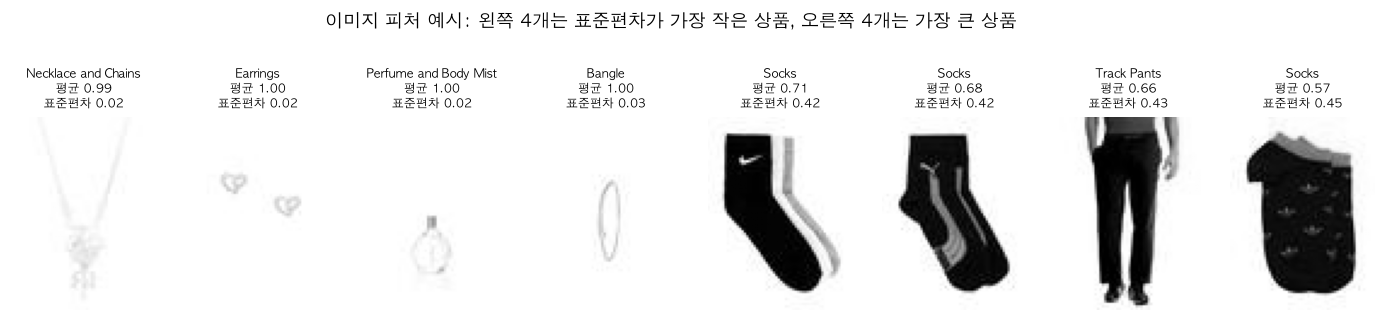

In [24]:
order = pr.df["img_std"].argsort().to_numpy()
picks = np.r_[order[:4], order[-4:]]
fig, axes = plt.subplots(1, 8, figsize=(16, 3.8))
for ax, i in zip(axes, picks):
    ax.imshow(images[i], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{pr.df['articleType'].iat[i]}\n평균 {pr.df['img_mean'].iat[i]:.2f}\n표준편차 {pr.df['img_std'].iat[i]:.2f}", fontsize=8)
    ax.axis("off")
fig.suptitle("이미지 피처 예시: 왼쪽 4개는 표준편차가 가장 작은 상품, 오른쪽 4개는 가장 큰 상품")
save_figure(fig, "image_feature_examples")
plt.show()

### 4-2. 텍스트: 상품명 단어 수와 글자 수

In [25]:
pr.add_text_features("productDisplayName", prefix="name")
sa.add_text_features("Description", prefix="desc")
print(pr.df[["name_word_count", "name_char_length"]].describe().loc[["mean", "50%", "min", "max"]])
print(sa.df[["desc_word_count", "desc_char_length"]].describe().loc[["mean", "50%", "min", "max"]])

      name_word_count  name_char_length
mean             5.73             34.35
50%              6.00             34.00
min              1.00             14.00
max             12.00             74.00
      desc_word_count  desc_char_length
mean             4.41             26.57
50%              4.00             27.00
min              1.00              8.00
max              8.00             35.00


**해석**

- 2,000장을 (80, 60) 흑백 배열로 쌓아 `images.mean(axis=(1, 2))`처럼 **축을 지정한 배열 연산 한 번**으로 평균과 표준편차를 구했다. 같은 값을 반복문으로 구한 결과와의 최대 차이는 0.0이다.
- 이미지 평균은 평균 0.84로 대부분 밝다. 상품 사진이 **흰 배경**으로 찍혀 있기 때문이다. 표준편차가 가장 작은 상품(0.02)은 흰 배경 위의 작은 목걸이·귀걸이·향수였고, 가장 큰 상품(0.42~0.45)은 검은 양말·바지처럼 흰 배경과 대비가 큰 어두운 상품이었다.
- 상품명은 평균 5.73단어(1~12단어), 거래 데이터의 상품명은 평균 4.41단어다.
- 시사점: 이 이미지 피처는 "상품이 얼마나 어둡고 화면을 얼마나 채우는가"를 수치로 나타낸다. 색상(`baseColour`)이나 카테고리를 예측하는 모델의 입력으로 쓸 수 있다.

### 4-3. 벡터 연산은 얼마나 빠른가

같은 계산(2,000장 각각의 밝기 평균)을 세 가지 방법으로 하고 시간을 잰다. 시간은 `timeit`으로 여러 번 재서 가장 빠른 값을 쓴다.

1. 순수 파이썬: 픽셀 4,800개를 파이썬 `sum`으로 더한다.
2. 반복문 + NumPy: 이미지 한 장씩 `img.mean()`을 부른다 (2,000번 호출).
3. 벡터 연산: `images.mean(axis=(1, 2))` 한 번.

In [26]:
import timeit

def best_time(func, number=3, repeat=5):
    return min(timeit.repeat(func, number=number, repeat=repeat)) / number

as_lists = images.tolist()
img_px = images.shape[1] * images.shape[2]
t_python = best_time(lambda: [sum(map(sum, img)) / img_px for img in as_lists], number=1, repeat=3)
t_loop = best_time(lambda: np.array([img.mean() for img in images]))
t_vec = best_time(lambda: images.mean(axis=(1, 2)))
# 값은 같지만 메모리에 띄엄띄엄 놓인 배열: 8칸마다 한 칸씩만 쓰는 넓은 배열의 뷰
spread = np.zeros((len(images), images.shape[1], images.shape[2] * 8), dtype=images.dtype)
spread[:, :, ::8] = images
scattered = spread[:, :, ::8]
assert np.array_equal(scattered, images) and not scattered.flags["C_CONTIGUOUS"]
t_f = best_time(lambda: scattered.mean(axis=(1, 2)))

speed = pd.DataFrame({"방법": ["순수 파이썬", "반복문 + NumPy", "벡터 연산 (연속 메모리)", "벡터 연산 (띄엄띄엄 놓인 메모리)"],
                      "시간 (ms)": [t_python * 1000, t_loop * 1000, t_vec * 1000, t_f * 1000]})
speed["벡터 연산 대비"] = speed["시간 (ms)"] / (t_vec * 1000)
print("C 순서(행 우선) 연속 배열인가:", images.flags["C_CONTIGUOUS"], "| 한 칸 크기:", images.itemsize, "바이트 | 전체", f"{images.nbytes / 1e6:.1f}MB")
speed

C 순서(행 우선) 연속 배열인가: True | 한 칸 크기: 4 바이트 | 전체 38.4MB


,방법,시간 (ms),벡터 연산 대비
0,순수 파이썬,103.38,21.02
1,반복문 + NumPy,23.46,4.77
2,벡터 연산 (연속 메모리),4.92,1.00
3,벡터 연산 (띄엄띄엄 놓인 메모리),20.08,4.08


**해석**

- 네 방법의 결과는 모두 같고 시간만 다르다. 시간은 실행할 때마다 조금씩 달라지므로 대략의 배수로 읽는다.
- 벡터 연산은 약 3~4ms다. 같은 NumPy라도 이미지마다 반복문을 돌리면 약 4~5배, 순수 파이썬은 약 20~30배 느리다.
- 빠른 이유는 세 가지다.
  - **해석 비용이 한 번뿐이다.** 파이썬 반복문은 한 바퀴마다 명령을 해석하고, 값의 타입을 확인하고, 숫자 객체를 새로 만든다. 벡터 연산은 이 일을 한 번만 하고, 나머지는 C로 짠 반복문이 처리한다.
  - **메모리가 연속이다.** `images`는 4바이트 숫자 1,920만 개가 빈틈없이 한 줄로 놓인 배열이다(38.4MB). CPU는 메모리를 64바이트 덩어리로 가져오므로, 한 번에 숫자 16개를 받는다. 같은 값을 8칸 간격으로 띄엄띄엄 놓은 배열은 덩어리 하나에서 2개만 쓰고 나머지를 버려서 **약 5~6배 느렸다**. 파이썬 리스트는 숫자 객체가 메모리 여기저기 흩어져 있고, 리스트에는 주소만 모여 있다.
  - **CPU가 여러 개를 한 번에 계산한다(SIMD).** 숫자가 한 줄로 붙어 있으면 CPU는 명령 하나로 여러 숫자를 동시에 더한다. 예를 들어 256비트 레지스터면 4바이트 숫자 8개다. NumPy의 합계·평균 내부 반복문이 이 명령을 쓴다. 띄엄띄엄 놓인 배열에서는 이 명령을 쓰기 어렵다. (SIMD만 따로 떼어 잰 값은 아니다.)

### 4-4. 이미지 처리의 병목: 어디가 느린가

이미지가 많아지면 어느 단계가 먼저 문제가 되는지 잰다. 단계는 (1) 파일 읽기와 디코딩(`plt.imread`), (2) 흑백 변환·자르기(`load_images`의 나머지), (3) 피처 계산(벡터 연산), (4) 메모리다.

In [27]:
from concurrent.futures import ThreadPoolExecutor
import time

paths = list(pr.df["image_path"][:500])
DataAnalyzer.load_images(paths[:20])          # 첫 실행의 파일 캐시 영향을 줄이려고 한 번 미리 읽는다
t0 = time.perf_counter(); raw_imgs = [plt.imread(p) for p in paths]; t1 = time.perf_counter()
DataAnalyzer.load_images(paths); t2 = time.perf_counter()
with ThreadPoolExecutor(4) as ex:
    list(ex.map(plt.imread, paths))
t3 = time.perf_counter()

per_decode = (t1 - t0) / len(paths)
per_load = (t2 - t1) / len(paths)
bottleneck = pd.DataFrame({
    "단계": ["읽기 + 디코딩 (imread)", "load_images 전체 (디코딩 + 흑백 + 자르기)", "읽기 + 디코딩, 스레드 4개", "피처 계산 (평균, 2,000장 벡터 연산)"],
    "1장당 (ms)": [f"{v:.4f}" for v in (per_decode * 1000, per_load * 1000, (t3 - t2) / len(paths) * 1000, t_vec / len(images) * 1000)]})
print("원본 이미지 한 장:", raw_imgs[0].shape, raw_imgs[0].dtype)
full_n = 44_441   # 원본 데이터셋 전체 이미지 수
print(f"전체 {full_n:,}장 예상: 로드 {per_load * full_n:.1f}초, float32 배열 {full_n * images[0].size * 4 / 1e6:,.0f}MB")
bottleneck

원본 이미지 한 장: (80, 60, 3) uint8
전체 44,441장 예상: 로드 19.4초, float32 배열 853MB


,단계,1장당 (ms)
0,읽기 + 디코딩 (imread),0.3352
1,load_images 전체 (디코딩 + 흑백 + 자르기),0.4377
2,"읽기 + 디코딩, 스레드 4개",0.5710
3,"피처 계산 (평균, 2,000장 벡터 연산)",0.0025


In [28]:
# 표본 추출: 2,000장만 써도 전체 경향을 알 수 있는가 (밝기 평균의 평균과 그 흔들림)
rng = np.random.default_rng(0)
rows = []
for n in [100, 500, 1000, 2000]:
    means = [pr.df["img_mean"].sample(n, random_state=int(s)).mean() if n < len(pr.df) else pr.df["img_mean"].mean()
             for s in rng.integers(0, 10_000, 200)]
    rows.append({"표본 수": n, "평균의 평균": f"{np.mean(means):.4f}",
                 "평균이 흔들리는 폭 (표준편차)": f"{np.std(means):.4f}",
                 "이론값 σ/√n": f"{pr.df['img_mean'].std() / np.sqrt(n):.4f}"})
pd.DataFrame(rows).set_index("표본 수")

,평균의 평균,평균이 흔들리는 폭 (표준편차),이론값 σ/√n
표본 수,,,
100,0.8345,0.0083,0.0089
500,0.8352,0.0033,0.0040
1000,0.8354,0.0018,0.0028
2000,0.8354,0.0000,0.0020


**해석**

- **가장 느린 단계는 파일 디코딩이다.**
  - JPG 한 장을 읽어 배열로 푸는 데 약 0.25ms, 흑백 변환과 자르기까지 약 0.3ms가 걸린다.
  - 피처 계산은 2,000장에 약 3ms로, 1장당 약 0.0015ms다. 디코딩이 100배 이상 느리다.
- 이번 이미지는 미러 데이터에서 이미 80×60으로 줄인 작은 파일이라 디코딩도 빠르다. 원본 크기의 사진이면 픽셀 수에 비례해 디코딩 시간이 늘어난다.
- 실제로 가장 오래 걸린 단계는 다운로드(네트워크)였다. 서버가 요청을 잠시 막아서(503) `scripts/download_data.py`가 기다렸다가 다시 시도했다.
- **스레드 4개로 나눠도 거의 빨라지지 않았다.** 실행할 때마다 조금 빠르거나 오히려 느렸다. 작업 하나(0.25ms)가 너무 작아서, 일을 나누고 모으는 비용이 아낀 시간보다 크다. 병렬화는 큰 이미지처럼 한 장의 디코딩이 오래 걸릴 때 효과가 있다.
- **전체 44,441장으로 늘리면 메모리가 먼저 문제다.**
  - 로드 시간은 약 10~20초로 견딜 만하다.
  - 하지만 float32 배열 하나가 853MB다. 그래서 2,000장씩 묶어(배치) 읽고 피처만 남긴 뒤 배열을 버리면, 메모리는 38MB 수준으로 유지된다.
- **표본 추출만으로도 경향은 충분히 보인다.**
  - 100장만 써도 밝기 평균의 평균은 0.8345로, 2,000장 전체(0.8354)와 0.001 차이다.
  - 표본 평균이 흔들리는 폭은 σ/√n 공식대로 표본 수의 제곱근에 반비례한다. 표본을 4배(100 → 400)로 늘리면 흔들림이 절반이 된다.
  - 2,000장 행은 전체를 다 쓴 것이라 흔들림이 0이다. 1,000장의 실제 흔들림(0.0018)이 이론값(0.0028)보다 작은 것도, 2,000장 중 절반을 뽑아 전체와 많이 겹치기 때문이다.
- 시사점: 이미지가 많아지면 ① 배치 처리로 메모리를 묶어 두고, ② 큰 이미지일 때만 프로세스 병렬화를 하고, ③ 탐색 단계에서는 표본으로 먼저 보는 순서로 대응한다.

## 5. 이상치 탐지와 처리 (IQR)

IQR(사분범위) = Q3 − Q1. 경계 [Q1 − 1.5 × IQR, Q3 + 1.5 × IQR] 밖을 이상치로 본다. 탐지 로직은 `DataAnalyzer.detect_outliers()`에 직접 구현했다.

In [29]:
rows = []
for col in ["Quantity", "Price", "amount"]:
    b = sa.iqr_bounds(col, threshold=1.5)
    n = len(sa.detect_outliers(col, threshold=1.5))
    rows.append({"컬럼": col, "Q1": b["q1"], "Q3": b["q3"], "IQR": b["iqr"], "하한": b["lower"],
                 "상한": b["upper"], "이상치 수": n, "이상치 비율(%)": n / len(sa.df) * 100})
outlier_table = pd.DataFrame(rows)
outlier_table

,컬럼,Q1,Q3,IQR,하한,상한,이상치 수,이상치 비율(%)
0,Quantity,1.00,12.00,11.00,-15.50,28.50,53019,5.28
1,Price,1.25,4.13,2.88,-3.07,8.45,75064,7.48
2,amount,4.13,17.70,13.57,-16.23,38.06,82136,8.19


### 5-1. 왜 IQR인가: 다른 기준과 비교

같은 거래 금액(`amount`)에 세 가지 기준을 적용해 몇 행이 이상치로 잡히는지 본다.

- **z-score**: (값 − 평균) ÷ 표준편차의 절댓값이 3보다 크면 이상치
- **IQR**: Q1 − 1.5 × IQR 아래, Q3 + 1.5 × IQR 위면 이상치
- **로그 IQR**: log₁₀(금액)에 IQR 규칙을 적용

In [30]:
a = sa.df["amount"]
z = (a - a.mean()) / a.std()
la = np.log10(a)
lq1, lq3 = la.quantile([0.25, 0.75])
liqr = lq3 - lq1
b = sa.iqr_bounds("amount")
crit = pd.DataFrame({
    "기준": ["z-score > 3", "IQR 1.5배", "IQR 3배", "로그 IQR 1.5배"],
    "경계(파운드)": [f"{a.mean() - 3 * a.std():.2f} ~ {a.mean() + 3 * a.std():.2f}", f"{b['lower']:.2f} ~ {b['upper']:.2f}",
                    f"{sa.iqr_bounds('amount', 3)['lower']:.2f} ~ {sa.iqr_bounds('amount', 3)['upper']:.2f}",
                    f"{10 ** (lq1 - 1.5 * liqr):.2f} ~ {10 ** (lq3 + 1.5 * liqr):.2f}"],
    "이상치 행 수": [int((z.abs() > 3).sum()), len(sa.detect_outliers("amount", 1.5)), len(sa.detect_outliers("amount", 3)),
                  int(((la < lq1 - 1.5 * liqr) | (la > lq3 + 1.5 * liqr)).sum())],
})
crit["비율(%)"] = crit["이상치 행 수"] / len(a) * 100
print(f"평균 {a.mean():.2f}, 표준편차 {a.std():.2f}, 중앙값 {a.median():.2f}")
crit

평균 19.58, 표준편차 199.98, 중앙값 10.08


,기준,경계(파운드),이상치 행 수,비율(%)
0,z-score > 3,-580.37 ~ 619.52,1396,0.14
1,IQR 1.5배,-16.23 ~ 38.06,82136,8.19
2,IQR 3배,-36.58 ~ 58.41,52211,5.20
3,로그 IQR 1.5배,0.47 ~ 157.04,19471,1.94


**해석**

- 거래 금액의 평균은 19.58파운드인데 표준편차가 199.98파운드다. 극단값이 표준편차 자체를 부풀려서, **z-score 기준(평균 ± 3 × 표준편차)은 −580 ~ 620파운드라는 넓은 범위**가 되고 이상치를 1,396행(0.14%)밖에 잡지 못한다. 꼬리가 긴 데이터에서는 기준을 만드는 평균·표준편차가 이상치에 오염되기 때문이다.
- IQR은 Q1, Q3만 쓰므로 극단값에 흔들리지 않는다. 대신 이 데이터는 원래 꼬리가 길어 **1.5배 기준으로 8.19%**, 3배 기준으로도 5.20%가 걸린다.
- 로그 축에서 IQR을 적용하면(0.47 ~ 157.04파운드) 1.94%만 걸린다. 금액처럼 "몇 배 차이"가 의미 있는 값은 로그로 본 분포가 대칭에 가까워서, 로그 IQR이 "정말 드문 값"에 더 가깝다.
- 이 과제는 명세대로 **보통 축의 IQR 1.5배**로 탐지하고, 처리 방법은 아래처럼 정체를 확인한 뒤 정했다. 기준을 하나로 정하기 전에 여러 기준을 비교해 보면, 데이터의 꼬리가 얼마나 긴지와 기준의 약점이 같이 보인다.

### 5-2. 기준을 넓히면, 그리고 이상치의 정체

In [31]:
# 3 × IQR로 기준을 넓히면 얼마나 남는지도 본다
for col in ["Quantity", "Price", "amount"]:
    print(f"{col}: 1.5×IQR {len(sa.detect_outliers(col, 1.5)):,}행, 3×IQR {len(sa.detect_outliers(col, 3)):,}행")
top = sa.detect_outliers("amount", 3).nlargest(5, "amount")[["Invoice", "Description", "Quantity", "Price", "amount", "Customer ID"]]
top

Quantity: 1.5×IQR 53,019행, 3×IQR 37,838행


Price: 1.5×IQR 75,064행, 3×IQR 20,234행


amount: 1.5×IQR 82,136행, 3×IQR 52,211행


,Invoice,Description,Quantity,Price,amount,Customer ID
1065882,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,"168,469.60",16446
587080,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,"77,183.60",12346
748132,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50,"38,970.00",15098
432176,530715,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,"15,818.40",15838
228042,511465,PINK PAPER PARASOL,3500,2.55,"8,925.00",18008


treat_outliers(amount, threshold=1.5, clip): 82,136행 (경계 -16.23 ~ 38.06)


[저장] outputs/outlier_before_after.png


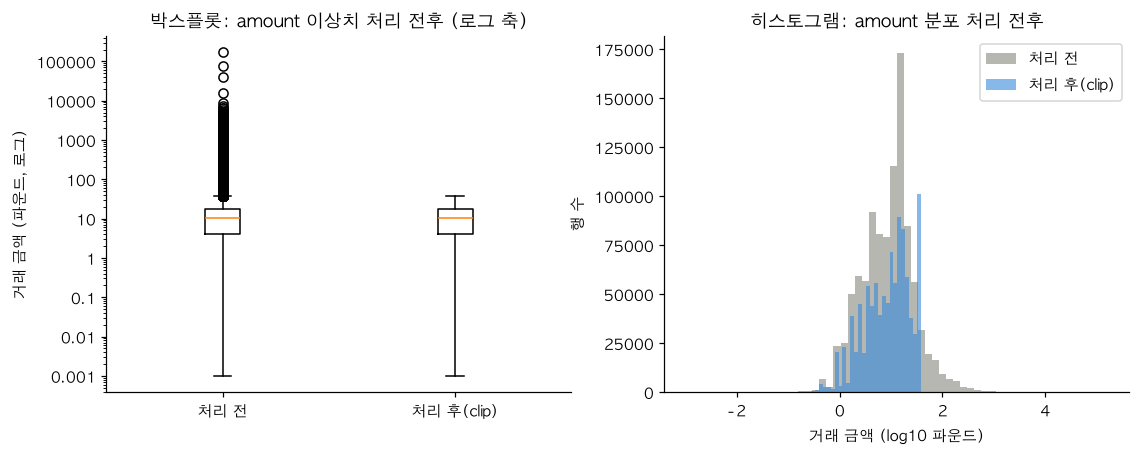

In [32]:
# 처리: 분포 분석용 사본에서 amount를 IQR 경계로 잘라 붙인다(clip). 행은 지우지 않는다.
# RFM의 Monetary는 실제 구매 금액이어야 하므로 원래 amount를 쓴다.
clipped = DataAnalyzer(df=sa.df[["amount", "Quantity", "Price"]])
n_clip = clipped.treat_outliers("amount", threshold=1.5, method="clip")
print(clipped.log[-1])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].boxplot([sa.df["amount"], clipped.df["amount"]], tick_labels=["처리 전", "처리 후(clip)"], showfliers=True)
axes[0].set_yscale("log")
plain_log_ticks(axes[0], "y")
axes[0].set(title="박스플롯: amount 이상치 처리 전후 (로그 축)", ylabel="거래 금액 (파운드, 로그)")
axes[1].hist(np.log10(sa.df["amount"]), bins=60, color=GRAY, alpha=0.6, label="처리 전")
axes[1].hist(np.log10(clipped.df["amount"]), bins=60, color=BLUE, alpha=0.6, label="처리 후(clip)")
axes[1].set(title="히스토그램: amount 분포 처리 전후", xlabel="거래 금액 (log10 파운드)", ylabel="행 수")
axes[1].legend()
save_figure(fig, "outlier_before_after")
plt.show()

**해석**

- 1.5 × IQR 기준이면 `Quantity`의 5.28%, `Price`의 7.48%, `amount`의 8.19%가 이상치다. 기준을 3 × IQR로 넓혀도 `amount`는 52,211행(5.20%)이 남는다.
- 금액 상위 이상치는 80,995개(168,469.60파운드), 74,215개 주문처럼 큰 수량 주문이다. 이 두 건은 곧바로 취소된 주문이라 RFM에서는 취소와 상쇄된다. 그 밖에 9,360개, 3,500개 같은 **실제 도매 대량 주문**이 대부분이다. 2장에서 비상품 코드를 먼저 뺐기 때문에, 이전에 섞여 있던 `Manual`(수동 조정, 25,111.09파운드) 같은 기록은 더 이상 이상치 목록에 없다.
- 도매 고객이 많아 금액 분포가 원래 오른쪽으로 길다. 이상치를 지우면 실제 VIP 매출을 지우게 된다. 그래서 **분포를 보는 사본에서만 경계값(38.06파운드)으로 잘라 붙이고(clip)**, RFM의 금액은 원래 값을 쓴다. 박스플롯에서 처리 후 수염 밖의 점이 사라지고, 히스토그램에서 경계값 위치에 잘린 값이 모인 것이 보인다.
- 시사점: IQR 이상치는 "오류"가 아니라 "드문 값"이라는 뜻이다. 오류(규칙 위반)는 2장에서 근거를 남기고 뺐고, 드문 값은 정체를 확인한 뒤 분석 목적에 따라 지울지, 자를지, 둘지를 정했다.

## 6. 통계 분석

### 6-1. 요약 통계

In [33]:
sa.summary_stats(["Quantity", "Price", "amount"])

,평균,중앙값,표준편차,Q1(25%),Q3(75%),최솟값,최댓값
Quantity,11.15,4.00,128.74,1.00,12.00,1.00,"80,995.00"
Price,3.34,2.10,4.75,1.25,4.13,0.00,"1,157.15"
amount,19.58,10.08,199.98,4.13,17.70,0.00,"168,469.60"


In [34]:
pr.summary_stats(["img_mean", "img_std", "name_word_count", "year"])

,평균,중앙값,표준편차,Q1(25%),Q3(75%),최솟값,최댓값
img_mean,0.84,0.84,0.09,0.78,0.90,0.42,1.00
img_std,0.25,0.26,0.08,0.19,0.31,0.02,0.45
name_word_count,5.73,6.00,1.37,5.00,7.00,1.00,12.00
year,"2,012.71","2,012.00",2.07,"2,011.00","2,015.00","2,010.00","2,018.00"


[저장] outputs/histograms.png


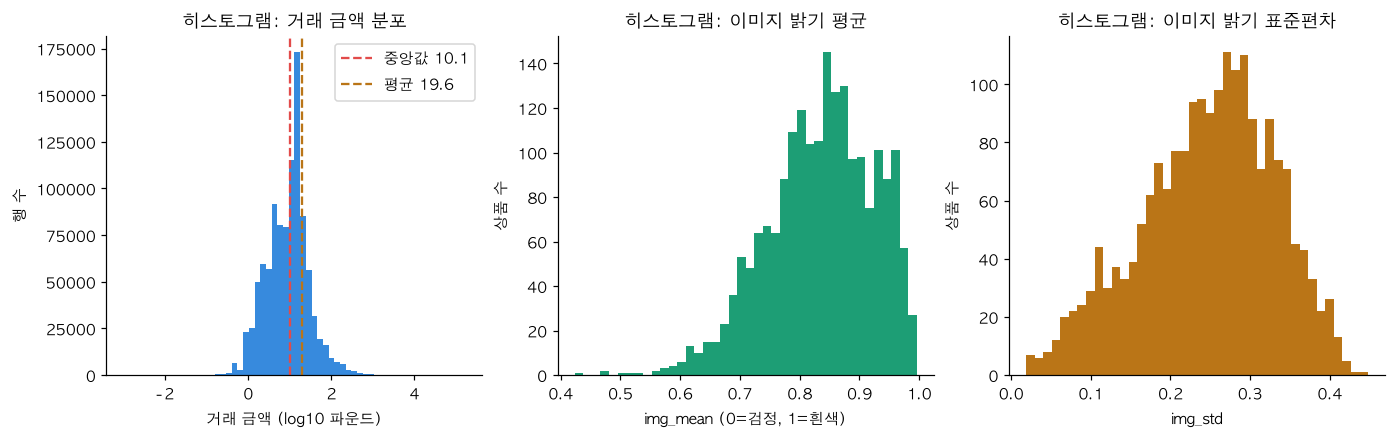

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(np.log10(sa.df["amount"]), bins=60, color=BLUE)
axes[0].axvline(np.log10(sa.df["amount"].median()), color=RED, ls="--", label=f"중앙값 {sa.df['amount'].median():.1f}")
axes[0].axvline(np.log10(sa.df["amount"].mean()), color=ORANGE, ls="--", label=f"평균 {sa.df['amount'].mean():.1f}")
axes[0].set(title="히스토그램: 거래 금액 분포", xlabel="거래 금액 (log10 파운드)", ylabel="행 수")
axes[0].legend()
axes[1].hist(pr.df["img_mean"], bins=40, color=GREEN)
axes[1].set(title="히스토그램: 이미지 밝기 평균", xlabel="img_mean (0=검정, 1=흰색)", ylabel="상품 수")
axes[2].hist(pr.df["img_std"], bins=40, color=ORANGE)
axes[2].set(title="히스토그램: 이미지 밝기 표준편차", xlabel="img_std", ylabel="상품 수")
save_figure(fig, "histograms")
plt.show()

**해석**

- 판매 데이터에서 `amount`(거래 금액)는 평균 19.58파운드, 중앙값 10.08파운드, 표준편차 199.98파운드다. 평균이 중앙값의 2배이고 표준편차가 평균의 10배다. **한 줄짜리 거래는 대부분 10파운드 안팎**이고, 아주 큰 거래 몇 건이 평균을 끌어올린다. `Price`도 평균 3.34, 중앙값 2.10으로 같은 모양이다.
- 사분위수로 보면 거래 금액의 가운데 50%는 4.13~17.70파운드 사이다.
- 상품 이미지 평균은 Q1 0.78 ~ Q3 0.90에 몰려 있고, 표준편차는 0.19 ~ 0.31 사이다.
- 시사점: 이 데이터에서 "평균 주문 금액"을 목표 지표로 쓰면 소수 도매 주문에 크게 흔들린다. 중앙값이나 로그 스케일 지표를 함께 봐야 한다.

### 6-2. 월별 매출 추이

[저장] outputs/monthly_revenue.png


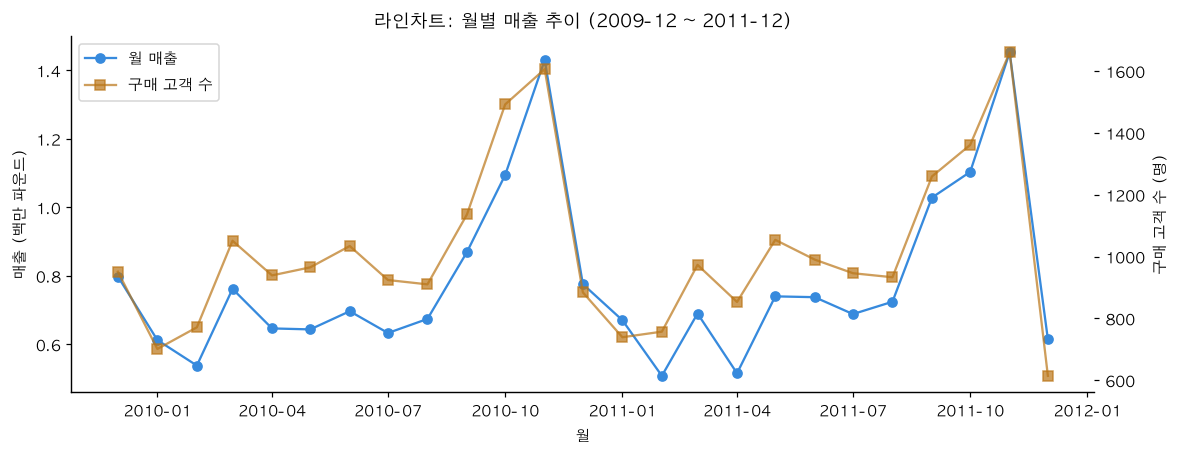

마지막 달은 2011-12-09까지만 있어 일부 기간이다.
InvoiceDate
2009-12-01   0.80
2010-01-01   0.61
2010-02-01   0.54
2010-03-01   0.76
2010-04-01   0.65
2010-05-01   0.64
2010-06-01   0.70
2010-07-01   0.63
2010-08-01   0.67
2010-09-01   0.87
2010-10-01   1.09
2010-11-01   1.43
2010-12-01   0.78
2011-01-01   0.67
2011-02-01   0.51
2011-03-01   0.69
2011-04-01   0.52
2011-05-01   0.74
2011-06-01   0.74
2011-07-01   0.69
2011-08-01   0.72
2011-09-01   1.03
2011-10-01   1.10
2011-11-01   1.45
2011-12-01   0.61
Freq: MS


In [36]:
monthly = sa.df.set_index("InvoiceDate")["amount"].resample("MS").sum()
monthly_cust = sa.df.dropna(subset=["Customer ID"]).set_index("InvoiceDate")["Customer ID"].resample("MS").nunique()
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(monthly.index, monthly / 1e6, marker="o", color=BLUE, label="월 매출")
ax.set(title="라인차트: 월별 매출 추이 (2009-12 ~ 2011-12)", xlabel="월", ylabel="매출 (백만 파운드)")
ax2 = ax.twinx()
ax2.plot(monthly_cust.index, monthly_cust, marker="s", color=ORANGE, alpha=0.7, label="구매 고객 수")
ax2.set_ylabel("구매 고객 수 (명)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")
save_figure(fig, "monthly_revenue")
plt.show()
print("마지막 달은 2011-12-09까지만 있어 일부 기간이다.")
print((monthly / 1e6).round(3).to_string())

**해석**

- 월 매출은 2010년 11월 143만 파운드, 2011년 11월 145만 파운드로 **두 해 모두 11월이 최고**다. 2011년 11월 매출은 같은 해 2월(51만 파운드)의 2.86배이고, 2011년 1~11월 매출 중 9~11월이 40.5%를 차지한다.
- 구매 고객 수도 매출과 같은 모양으로 오르내린다. 매출이 늘어난 이유가 주문 크기보다 **고객 수 증가**에 있다는 뜻이다.
- 2011년 12월은 9일까지만 있어 낮게 보이는 것이다. 2010년 12월도 78만 파운드로 낮다. 정리 전에는 두 시트가 겹친 12월 1~9일이 두 번 세어져 126만 파운드였고, 중복만 지우면 82만, 비상품 코드까지 빼면 78만 파운드다(2장).
- 시사점: 크리스마스 선물용품을 파는 회사라 매출이 9~11월에 몰린다. 재고와 마케팅은 9월 이전에 준비해야 한다.

## 7. RFM 기반 고객 세분화

- **Recency**: 기준일(마지막 거래일 다음 날) − 고객의 마지막 구매일 (일)
- **Frequency**: 서로 다른 주문(Invoice) 수
- **Monetary**: 순 구매 금액 = 구매 금액 − 취소 금액. 취소 주문(Invoice가 C로 시작)은 Recency·Frequency 계산에서는 빼고, 금액에서는 뺀다. 순 구매 금액이 0 이하인 고객(취소가 구매보다 많은 고객)은 제외한다.

각 값을 고객 순위로 5등분해 1~5점을 준다(Recency는 최근일수록 5점). 세그먼트 규칙은 위에서부터 먼저 맞는 것을 적용한다.

| 세그먼트 | 규칙 | 뜻 |
|---|---|---|
| VIP | R ≥ 4, F ≥ 4, M ≥ 4 | 최근에, 자주, 많이 산다 |
| Loyal | R ≥ 3, F ≥ 3 | 꾸준히 산다 |
| New | R ≥ 4, F ≤ 2 | 최근에 처음(또는 두 번째)으로 샀다 |
| At Risk | R ≤ 2, F ≥ 3 | 자주 샀지만 한동안 안 온다 |
| Churned | R ≤ 2, F ≤ 2 | 오래전에 조금 사고 떠났다 |
| Potential | 나머지 | 중간 고객 |

In [37]:
ra = DataAnalyzer(df=rfm_base)
rfm = ra.calculate_rfm("Customer ID", "InvoiceDate", "amount", invoice_col="Invoice", cancel_prefix="C")
print(ra.log[-1])

# 취소를 빼지 않았다면 얼마나 달라지는지: 취소 영향이 가장 큰 고객 5명
gross = sa.df.dropna(subset=["Customer ID"]).groupby("Customer ID")["amount"].sum()
cmp = pd.DataFrame({"취소 무시 금액": gross.reindex(rfm.index), "순 구매 금액": rfm["Monetary"]})
cmp["차이"] = cmp["취소 무시 금액"] - cmp["순 구매 금액"]
print(f"취소로 금액이 줄어든 고객: {(cmp['차이'] > 0.005).sum():,}명")
cmp.nlargest(5, "차이")
rfm.head()

calculate_rfm: 고객 5,838명, 기준일 2011-12-10, 순 구매 금액 0 이하 14명 제외


취소로 금액이 줄어든 고객: 2,408명


,Recency,Frequency,Monetary,R,F,M,RFM_score,segment
Customer ID,,,,,,,,
12346,325,3,169.36,2,3,1,6,At Risk
12347,2,8,"4,921.53",5,4,5,14,VIP
12348,75,5,"1,658.40",3,4,4,11,Loyal
12349,18,3,"3,654.54",5,3,5,13,Loyal
12350,310,1,294.40,2,1,2,5,Churned


In [38]:
rfm[["Recency", "Frequency", "Monetary"]].describe()

,Recency,Frequency,Monetary
count,"5,838.00","5,838.00","5,838.00"
mean,199.43,6.27,"2,802.59"
std,208.40,12.76,"13,841.09"
min,0.00,1.00,0.00
25%,25.00,1.00,332.69
50%,95.00,3.00,842.41
75%,378.00,7.00,"2,173.60"
max,738.00,373.00,"578,408.64"


In [39]:
seg_order = ["VIP", "Loyal", "Potential", "New", "At Risk", "Churned"]
seg = (rfm.groupby("segment")
       .agg(고객수=("Recency", "size"), 평균_Recency=("Recency", "mean"), 평균_Frequency=("Frequency", "mean"),
            평균_Monetary=("Monetary", "mean"), 중앙_Monetary=("Monetary", "median"), 매출합=("Monetary", "sum"))
       .reindex(seg_order))
seg["고객비중(%)"] = seg["고객수"] / seg["고객수"].sum() * 100
seg["매출비중(%)"] = seg["매출합"] / seg["매출합"].sum() * 100
seg

,고객수,평균_Recency,평균_Frequency,평균_Monetary,중앙_Monetary,매출합,고객비중(%),매출비중(%)
segment,,,,,,,,
VIP,1274,19.00,17.09,"8,869.45","3,844.86","11,299,683.21",21.82,69.06
Loyal,1401,69.82,5.42,"1,836.78","1,067.75","2,573,335.23",24.00,15.73
Potential,382,105.08,1.36,526.33,354.29,"201,059.88",6.54,1.23
New,446,27.24,1.47,538.51,363.77,"240,176.96",7.64,1.47
At Risk,828,365.89,5.00,"1,738.15","1,005.13","1,439,186.53",14.18,8.80
Churned,1507,455.89,1.25,403.52,267.90,"608,106.48",25.81,3.72


[저장] outputs/rfm_segments_bar.png


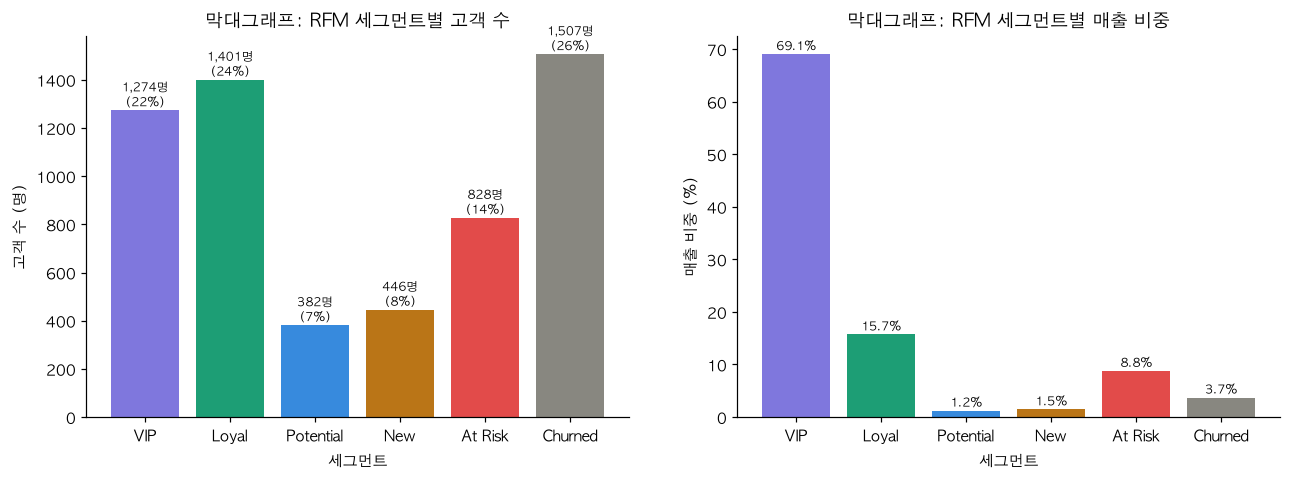

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
colors = [SEGMENT_COLORS[s] for s in seg_order]
bars = axes[0].bar(seg_order, seg["고객수"], color=colors)
axes[0].bar_label(bars, labels=[f"{n:,}명\n({p:.0f}%)" for n, p in zip(seg["고객수"], seg["고객비중(%)"])], fontsize=8)
axes[0].set(title="막대그래프: RFM 세그먼트별 고객 수", xlabel="세그먼트", ylabel="고객 수 (명)")
bars = axes[1].bar(seg_order, seg["매출비중(%)"], color=colors)
axes[1].bar_label(bars, fmt="%.1f%%", fontsize=8)
axes[1].set(title="막대그래프: RFM 세그먼트별 매출 비중", xlabel="세그먼트", ylabel="매출 비중 (%)")
save_figure(fig, "rfm_segments_bar")
plt.show()

[저장] outputs/rfm_heatmap_scatter.png


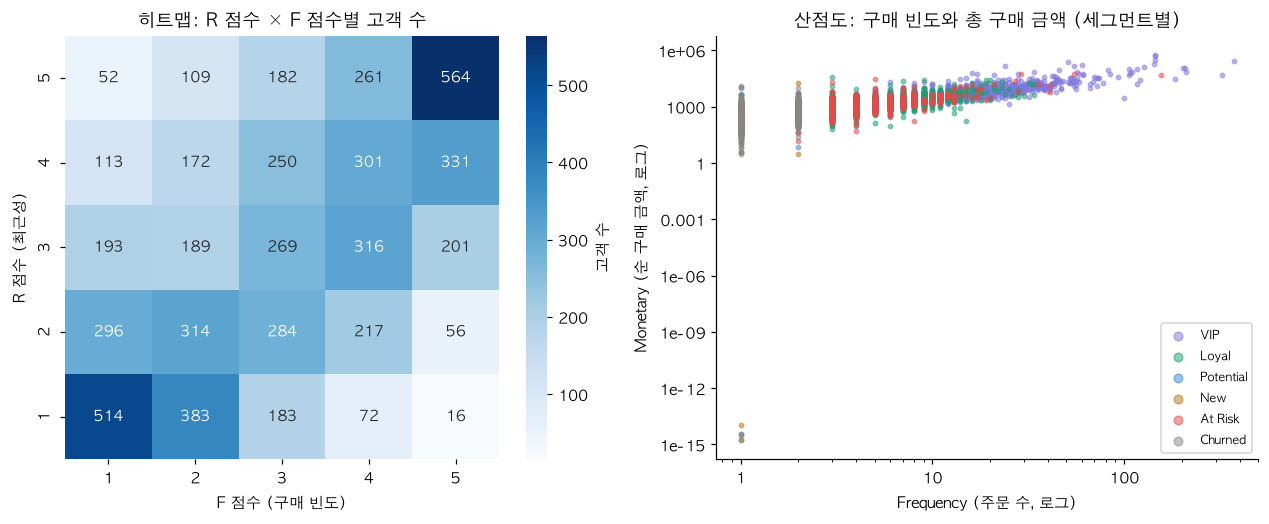

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
counts = pd.crosstab(rfm["R"], rfm["F"]).sort_index(ascending=False)
sns.heatmap(counts, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar_kws={"label": "고객 수"})
axes[0].set(title="히트맵: R 점수 × F 점수별 고객 수", xlabel="F 점수 (구매 빈도)", ylabel="R 점수 (최근성)")
for s in seg_order:
    m = rfm["segment"] == s
    axes[1].scatter(rfm.loc[m, "Frequency"], rfm.loc[m, "Monetary"], s=8, alpha=0.5, color=SEGMENT_COLORS[s], label=s)
axes[1].set(xscale="log", yscale="log", title="산점도: 구매 빈도와 총 구매 금액 (세그먼트별)",
            xlabel="Frequency (주문 수, 로그)", ylabel="Monetary (순 구매 금액, 로그)")
plain_log_ticks(axes[1], "x"); plain_log_ticks(axes[1], "y")
axes[1].legend(markerscale=2, fontsize=8)
save_figure(fig, "rfm_heatmap_scatter")
plt.show()

**해석**

- 고객 5,838명을 6개 세그먼트로 나눴다(순 구매 금액이 0 이하인 14명 제외). 취소를 반영하지 않았다면 2,408명의 금액이 부풀려졌을 것이다. 예를 들어 80,995개를 주문했다가 전부 취소한 고객은 VIP처럼 보였을 것이다.
- **VIP 1,274명(21.8%)이 매출의 69.1%**를 낸다. 평균 19일 전에 마지막으로 샀고, 2년간 평균 17.1번 주문했다.
- **At Risk 828명(14.2%)**은 평균 5.0번 주문한 단골이었지만, 평균 366일 동안 오지 않았다. 매출의 8.8%다.
- Churned 1,507명(25.8%)은 고객 수로는 가장 많지만 매출은 3.7%다.
- R × F 히트맵에서 고객이 대각선 양 끝(R5·F5 564명, R1·F1 514명)에 몰린다. 최근에 온 고객이 자주 오는 고객이기도 하다는 뜻이다.
- 산점도에서 VIP(보라)는 오른쪽 위, Churned(회색)는 왼쪽 아래에 모인다. 주문이 늘수록 금액도 함께 늘어나는 모양이다.

## 8. 상관 분석

**상관계수**는 "x가 클 때 y도 큰가?"를 −1 ~ 1의 숫자 하나로 나타낸다. 1이면 함께, −1이면 반대로 움직이고, 0이면 한쪽을 알아도 다른 쪽을 짐작할 수 없다. 두 가지를 함께 계산한다.

- **Pearson**: 두 변수가 **직선**에 얼마나 가깝게 함께 움직이나. 값 그대로 계산해서 크기 차이까지 반영하지만, 극단값에 흔들린다.
- **Spearman**: 한쪽이 커질 때 다른 쪽도 **한 방향으로만** 움직이나. 값을 순위로 바꾼 뒤 Pearson을 계산해서, 극단값과 곡선 관계에 강하다.
- 둘이 크게 다르면 그 자체가 신호다. Spearman이 더 크면 극단값이나 곡선 관계, Pearson이 더 크면 극단값 몇 개가 만든 가짜 관계를 의심한다.

각 쌍은 확인하려던 질문이 있다.

| 쌍 | 확인하려던 질문 | 종류 |
|---|---|---|
| Frequency – Monetary | RFM의 F와 M은 서로 다른 정보인가, 겹치나? | 비즈니스 |
| Recency – Frequency | 최근에 온 고객이 자주 오는 고객인가? | 비즈니스 |
| Quantity – Price | 싸면 많이 사는가? (도매 구조) | 비즈니스 |
| img_mean – img_std | 두 이미지 피처가 같은 정보를 담아 겹치나? | 피처 설계 |
| name_word_count – img_std | 텍스트 피처와 이미지 피처는 서로 다른 정보인가? | 피처 설계 |

In [42]:
ca = DataAnalyzer(df=rfm)
corr_rfm = pd.concat([ca.correlations([("Frequency", "Monetary"), ("Recency", "Frequency"), ("Recency", "Monetary")], "pearson"),
                      ca.correlations([("Frequency", "Monetary"), ("Recency", "Frequency"), ("Recency", "Monetary")], "spearman").iloc[:, 2]], axis=1)
corr_rfm

,변수1,변수2,상관계수(pearson),상관계수(spearman)
0,Frequency,Monetary,0.62,0.86
1,Recency,Frequency,-0.26,-0.56
2,Recency,Monetary,-0.12,-0.51


In [43]:
corr_tx = pd.concat([sa.correlations([("Quantity", "Price")], "pearson"),
                     sa.correlations([("Quantity", "Price")], "spearman").iloc[:, 2]], axis=1)
corr_pr = pd.concat([pr.correlations([("img_mean", "img_std"), ("name_word_count", "img_std"), ("year", "img_mean")], "pearson"),
                     pr.correlations([("img_mean", "img_std"), ("name_word_count", "img_std"), ("year", "img_mean")], "spearman").iloc[:, 2]], axis=1)
pd.concat([corr_tx, corr_pr], ignore_index=True)

,변수1,변수2,상관계수(pearson),상관계수(spearman)
0,Quantity,Price,-0.03,-0.43
1,img_mean,img_std,-0.82,-0.84
2,name_word_count,img_std,0.02,0.03
3,year,img_mean,0.11,0.16


[저장] outputs/correlation_heatmaps.png


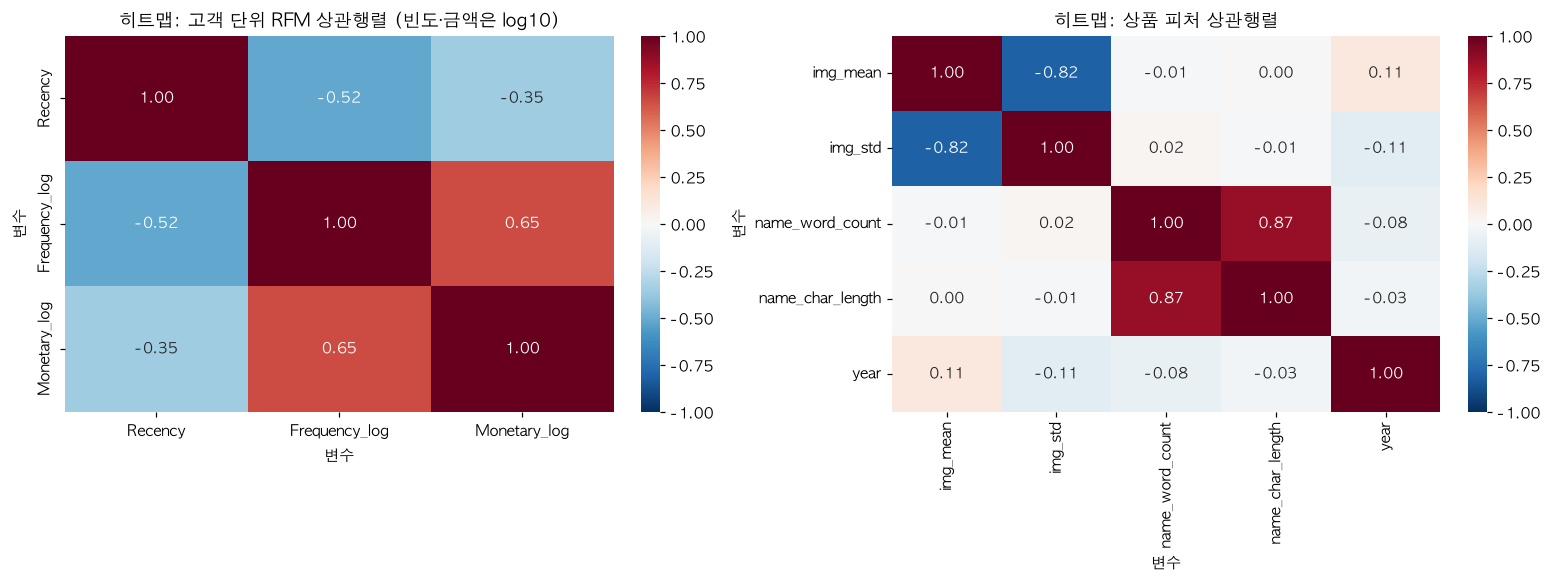

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), layout="constrained")
cust = rfm[["Recency", "Frequency", "Monetary"]].assign(Frequency_log=np.log10(rfm["Frequency"]), Monetary_log=np.log10(rfm["Monetary"]))
sns.heatmap(cust[["Recency", "Frequency_log", "Monetary_log"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0])
axes[0].set(title="히트맵: 고객 단위 RFM 상관행렬 (빈도·금액은 log10)", xlabel="변수", ylabel="변수")
sns.heatmap(pr.df[["img_mean", "img_std", "name_word_count", "name_char_length", "year"]].corr(), annot=True, fmt=".2f",
            cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1])
axes[1].set(title="히트맵: 상품 피처 상관행렬", xlabel="변수", ylabel="변수")
save_figure(fig, "correlation_heatmaps")
plt.show()

[저장] outputs/product_scatter_bar.png


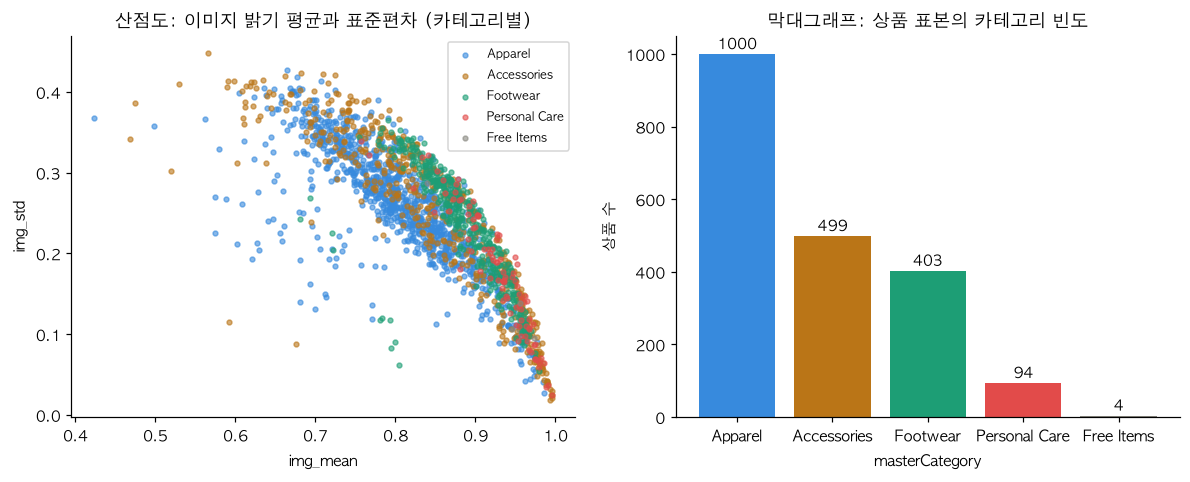

,img_mean,img_std,name_word_count
masterCategory,,,
Accessories,0.84,0.25,5.46
Apparel,0.80,0.26,5.83
Footwear,0.89,0.23,5.79
Free Items,0.93,0.16,5.25
Personal Care,0.93,0.18,5.89


In [45]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cat_colors = {"Apparel": BLUE, "Accessories": ORANGE, "Footwear": GREEN, "Personal Care": RED, "Free Items": GRAY}
for c, col in cat_colors.items():
    m = pr.df["masterCategory"] == c
    axes[0].scatter(pr.df.loc[m, "img_mean"], pr.df.loc[m, "img_std"], s=10, alpha=0.6, color=col, label=c)
axes[0].set(title="산점도: 이미지 밝기 평균과 표준편차 (카테고리별)", xlabel="img_mean", ylabel="img_std")
axes[0].legend(fontsize=8)
cnt = pr.df["masterCategory"].value_counts()
bars = axes[1].bar(cnt.index, cnt.values, color=[cat_colors[c] for c in cnt.index])
axes[1].bar_label(bars)
axes[1].set(title="막대그래프: 상품 표본의 카테고리 빈도", xlabel="masterCategory", ylabel="상품 수")
save_figure(fig, "product_scatter_bar")
plt.show()
pr.df.groupby("masterCategory")[["img_mean", "img_std", "name_word_count"]].mean()

**해석**

| 변수 쌍 | Pearson | Spearman | 해석 |
|---|---|---|---|
| Frequency – Monetary | 0.62 | **0.86** | 자주 사는 고객이 많이 쓴다. 극단값의 영향을 덜 받는 순위 상관이 더 강하다 |
| Recency – Frequency | −0.26 | **−0.56** | 최근에 온 고객일수록 주문 수가 많다 |
| Quantity – Price | −0.03 | **−0.43** | 직선 관계는 없지만, 순위로 보면 싼 상품일수록 많이 산다 |
| img_mean – img_std | −0.82 | −0.84 | 밝은(흰 배경이 많은) 이미지일수록 대비가 작다 |
| name_word_count – img_std | 0.02 | 0.03 | 상품명 길이와 이미지 대비는 관계가 없다 |

- `Quantity`와 `Price`의 Pearson 상관은 −0.03이지만 Spearman은 −0.43이다. 소수의 극단값이 직선 관계를 가리고 있었다는 뜻이다. **꼬리가 긴 데이터에서는 Spearman도 함께 봐야 한다.**
- Spearman은 SciPy 없이 "순위로 바꾼 뒤 Pearson"으로 직접 계산했다(`DataAnalyzer.correlations`).
- 시사점: 주문 빈도와 금액이 강하게 함께 움직이므로, 구매 빈도를 늘리는 활동(재구매 알림, 정기 주문)이 매출 증대로 이어질 가능성이 크다. 다만 상관은 인과가 아니다.

### 8-1. 스케일링: 단위가 다른 값을 같은 눈금으로

R, F, M은 단위가 다르다. Recency는 **일**(0 ~ 738), Frequency는 **회**(1 ~ 373), Monetary는 **파운드**(0 ~ 578,408)다. 이 값들을 그대로 써서 "두 고객이 얼마나 비슷한가"를 거리로 재면, 숫자가 큰 Monetary가 거리를 거의 다 차지한다. 다음 머신러닝 과제의 군집화(k-means)나 거리 기반 모델은 모두 이 거리를 쓰므로, 먼저 **눈금을 맞추는 일(스케일링)** 이 필요하다.

`DataAnalyzer.scale()`로 네 가지 방법을 적용한다. 모두 `(값 − 중심) ÷ 폭` 한 줄이고, 방법마다 중심과 폭만 다르다.

| 방법 | 중심 | 폭 | 결과 |
|---|---|---|---|
| 표준화 (standard) | 평균 | 표준편차 | 평균 0, 표준편차 1 |
| Min-Max | 최솟값 | 최댓값 − 최솟값 | 0 ~ 1 |
| 로버스트 (robust) | 중앙값 | IQR | 가운데 50%가 폭 1 |
| 로그 (log) | - | - | log(1 + 값). "몇 배 차이"를 "몇 칸 차이"로 |

이 과제에서는 이미 스케일링을 세 번 했다. 픽셀 값을 255로 나눠 0 ~ 1로 맞춘 것(Min-Max와 같은 생각), 거래 금액을 로그 축으로 그린 것, RFM 점수를 순위 5등분으로 매긴 것(순위 스케일링)이다.

In [46]:
cols = ["Recency", "Frequency", "Monetary"]
sc = DataAnalyzer(df=rfm[cols].copy())
for m in ["standard", "minmax", "robust", "log"]:
    sc.scale(cols, method=m)
sc.scale([f"{c}_log" for c in cols], method="standard", suffix="std")   # 로그로 꼬리를 줄인 뒤 표준화

# 무작위로 고른 고객 2만 쌍의 거리(유클리드 거리의 제곱)에서 R, F, M이 각각 몇 %를 차지하나
rng = np.random.default_rng(42)
i, j = rng.integers(0, len(sc.df), 20_000), rng.integers(0, len(sc.df), 20_000)
methods = {"원래 값": "", "표준화": "_standard", "Min-Max": "_minmax", "로버스트": "_robust", "로그 → 표준화": "_log_std"}
share_rows = []
for name, sfx in methods.items():
    X = sc.df[[c + sfx for c in cols]].to_numpy()
    sq = (X[i] - X[j]) ** 2
    share = sq.sum(axis=0) / sq.sum() * 100
    m_col = sc.df["Monetary" + sfx]
    share_rows.append({"방법": name, "R 비중 (%)": share[0], "F 비중 (%)": share[1], "M 비중 (%)": share[2],
                       "M 최솟값": m_col.min(), "M 중앙값": m_col.median(), "M 최댓값": m_col.max()})
share_table = pd.DataFrame(share_rows).set_index("방법")
share_table

,R 비중 (%),F 비중 (%),M 비중 (%),M 최솟값,M 중앙값,M 최댓값
방법,,,,,,
원래 값,0.03,0.00,99.97,0.00,842.41,"578,408.64"
표준화,37.36,34.36,28.29,-0.20,-0.14,41.59
Min-Max,98.13,1.33,0.53,0.00,0.00,1.00
로버스트,0.74,8.79,90.47,-0.46,0.00,313.74
로그 → 표준화,33.29,33.17,33.54,-4.87,-0.03,4.66


[저장] outputs/scaling_methods.png


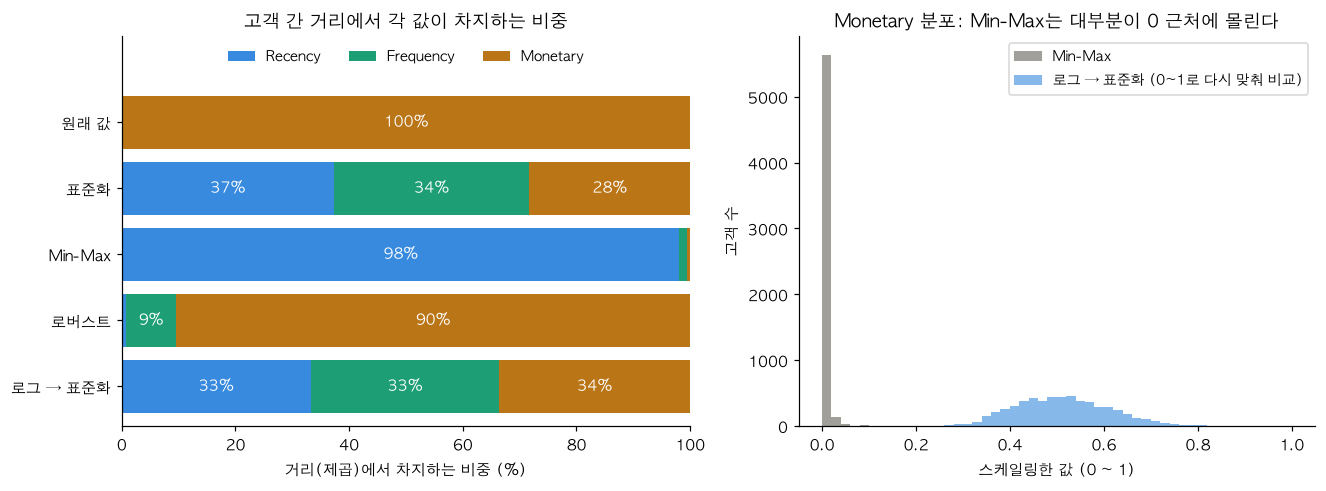

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
names = list(share_table.index)[::-1]
left = np.zeros(len(names))
for col, color, label in [("R 비중 (%)", BLUE, "Recency"), ("F 비중 (%)", GREEN, "Frequency"), ("M 비중 (%)", ORANGE, "Monetary")]:
    vals = share_table.loc[names, col].to_numpy()
    axes[0].barh(names, vals, left=left, color=color, label=label)
    for y, (l, v) in enumerate(zip(left, vals)):
        if v >= 6:
            axes[0].text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=10)
    left += vals
axes[0].set_xlim(0, 100)
axes[0].set_title("고객 간 거리에서 각 값이 차지하는 비중")
axes[0].set_xlabel("거리(제곱)에서 차지하는 비중 (%)")
axes[0].set_ylim(-0.6, len(names) + 0.3)
axes[0].legend(loc="upper center", ncols=3, fontsize=9, frameon=False)

mm = sc.df["Monetary_minmax"]
axes[1].hist(mm, bins=50, color=GRAY, alpha=0.8, label="Min-Max")
axes[1].hist((sc.df["Monetary_log_std"] - sc.df["Monetary_log_std"].min()) /
             (sc.df["Monetary_log_std"].max() - sc.df["Monetary_log_std"].min()),
             bins=50, color=BLUE, alpha=0.6, label="로그 → 표준화 (0~1로 다시 맞춰 비교)")
axes[1].set_title("Monetary 분포: Min-Max는 대부분이 0 근처에 몰린다")
axes[1].set_xlabel("스케일링한 값 (0 ~ 1)")
axes[1].set_ylabel("고객 수")
axes[1].legend(fontsize=9)
save_figure(fig, "scaling_methods")
plt.show()

In [48]:
# 데이터 누수 방지: 기준(평균, 표준편차)은 학습용 고객으로만 계산하고, 시험용 고객에는 그 기준을 그대로 쓴다
idx = rng.permutation(len(rfm))
cut = int(len(rfm) * 0.8)
train = DataAnalyzer(df=rfm[cols].iloc[idx[:cut]].copy())
test = DataAnalyzer(df=rfm[cols].iloc[idx[cut:]].copy())
train_params = train.scale(cols, method="standard")             # 학습용으로 기준을 계산
test.scale(cols, method="standard", params=train_params)       # 시험용은 계산하지 않고 그 기준을 적용
print("학습용에서 계산한 기준 (평균, 표준편차):")
for c, (center, width) in train_params.items():
    print(f"  {c}: 평균 {center:,.2f}, 표준편차 {width:,.2f}")
pd.concat({"학습용": train.df[[c + "_standard" for c in cols]].agg(["mean", "std"]),
           "시험용": test.df[[c + "_standard" for c in cols]].agg(["mean", "std"])}).round(3)

학습용에서 계산한 기준 (평균, 표준편차):
  Recency: 평균 201.39, 표준편차 208.82
  Frequency: 평균 6.07, 표준편차 10.75
  Monetary: 평균 2,644.64, 표준편차 11,541.57


Recency_standard  Frequency_standard  Monetary_standard
학습용 mean              0.00               -0.00               0.00
    std               1.00                1.00               1.00
시험용 mean             -0.05                0.09               0.07
    std               0.99                1.75               1.79

**해석**

- **원래 값**: 고객 사이 거리의 99.97%를 Monetary가 차지한다. 금액은 수만 단위로 차이 나고 Recency는 수백, Frequency는 수십 단위라서, R과 F는 거리에 거의 반영되지 않는다. 이대로 고객을 묶으면 "금액이 비슷한 고객"끼리만 묶인다.
- **Min-Max**: 이번에는 Recency가 98%를 차지한다.
  - Monetary의 최댓값(578,408파운드)이 너무 커서 폭이 거의 그 값이 된다.
  - 그래서 고객의 91%가 0.01보다 작은 값에 몰리고, 중앙값은 0.0015다(오른쪽 그림).
  - Frequency도 최댓값 373회 때문에 같은 일이 생긴다. 고르게 퍼진 Recency만 0 ~ 1을 다 쓴다.
  - Min-Max는 극단값 하나가 전체의 기준이 되는 방법이라, 꼬리가 긴 데이터에는 맞지 않는다.
- **로버스트**: 중앙값과 IQR을 기준으로 써서 기준 자체는 극단값에 흔들리지 않는다. 하지만 값을 줄여 주지는 않는다. Monetary의 최댓값이 313.74(IQR의 300배)로 남아, Monetary가 다시 90%를 차지한다.
- **표준화**: 평균으로 보면 37 : 34 : 28로 고르다. 하지만 Monetary 최댓값이 41.59(표준편차의 41배)라서, 극단적인 고객 몇 명이 끼는 거리는 여전히 Monetary가 결정한다. 또 평균과 표준편차가 극단값에 부풀려진 기준이다(5-1절 z-score와 같은 문제).
- **로그 → 표준화**: 33 : 33 : 34로 세 값이 거리에 똑같이 반영되고, 값의 범위도 −4.87 ~ 4.66으로 고르다. 로그가 "몇 배 차이"를 "몇 칸 차이"로 바꿔 꼬리를 먼저 줄이고, 그다음 표준화가 단위를 맞추기 때문이다. **꼬리가 긴 RFM 값에는 이 조합이 맞다.**
- **데이터 누수 방지**:
  - 학습용 고객(80%)으로 평균과 표준편차를 계산하고, 시험용 고객(20%)에는 그 기준을 그대로 적용했다(`scale(..., params=train_params)`).
  - 그래서 시험용의 평균은 정확히 0이 아니고(−0.05, 0.09, 0.07), 표준편차도 1이 아니다(Frequency 1.75, Monetary 1.79). 이것이 정상이다.
  - 시험용 데이터로 기준을 다시 계산하면, 모델이 시험 데이터의 정보를 미리 보는 셈이 된다. 9-1절의 이탈 예측 모델을 만들 때도 이 순서를 지킨다.
- 시사점: 스케일링 방법은 "모든 데이터에 맞는 정답"이 없다. 먼저 분포(꼬리 길이, 극단값)를 보고 고른다. RFM처럼 꼬리가 긴 값은 로그 후 표준화, 픽셀처럼 범위가 정해진 값(0 ~ 255)은 Min-Max가 자연스럽다.

## 9. 비즈니스 인사이트

같은 내용을 README.md에도 정리했다.

In [49]:
# 인사이트 근거 수치
vip, risk, churn, new = (rfm[rfm["segment"] == s] for s in ["VIP", "At Risk", "Churned", "New"])
print(f"VIP: {len(vip):,}명 ({len(vip) / len(rfm) * 100:.1f}%)이 매출의 {vip['Monetary'].sum() / rfm['Monetary'].sum() * 100:.1f}%")
print(f"At Risk: {len(risk):,}명, 평균 {risk['Recency'].mean():.0f}일 미방문, 평균 주문 {risk['Frequency'].mean():.1f}회, 매출 합 {risk['Monetary'].sum():,.0f}파운드")
print(f"New: {len(new):,}명, 평균 주문 {new['Frequency'].mean():.1f}회, 평균 금액 {new['Monetary'].mean():,.0f}파운드")
one = (rfm["Frequency"] == 1).mean() * 100
print(f"한 번만 주문한 고객 비율: {one:.1f}%")
top1 = rfm["Monetary"].nlargest(int(len(rfm) * 0.01)).sum() / rfm["Monetary"].sum() * 100
print(f"상위 1% 고객의 매출 비중: {top1:.1f}%")
q4 = monthly["2010-09":"2010-11"].sum() / monthly["2010-01":"2010-12"].sum() * 100
print(f"2010년 매출 중 9~11월 비중: {q4:.1f}%")

VIP: 1,274명 (21.8%)이 매출의 69.1%
At Risk: 828명, 평균 366일 미방문, 평균 주문 5.0회, 매출 합 1,439,187파운드
New: 446명, 평균 주문 1.5회, 평균 금액 539파운드
한 번만 주문한 고객 비율: 27.5%
상위 1% 고객의 매출 비중: 31.1%
2010년 매출 중 9~11월 비중: 36.2%


**인사이트 1. 매출의 69%가 고객 22%(VIP)에게서 나온다**

- (근거) VIP 1,274명(전체의 21.8%)이 순 매출의 69.1%(1,130만 파운드)를 냈다. 상위 1% 고객만으로도 매출의 31.1%다(세그먼트별 매출 비중 막대그래프).
- (실행) VIP 대상 → 대량 구매 할인 단가, 전담 담당자, 신상품 선공개 같은 전용 혜택 → VIP 이탈을 막는다. VIP 1명이 떠나면 평균 8,869파운드(2년 순 구매 금액)를 잃는다.
- (검증) VIP 중 도매업체와 개인 고객이 얼마나 섞여 있는지 알 수 있는 고객 유형 데이터가 추가로 필요하다. 도매업체라면 할인보다 결제 조건이나 배송 혜택이 더 효과적일 수 있다.

**인사이트 2. 단골이었다가 1년 가까이 오지 않는 At Risk 고객이 828명 있다**

- (근거) At Risk 828명(14.2%)은 2년간 평균 5.0번 주문했지만 평균 366일 동안 구매가 없다. 이 고객들의 순 구매 금액 합은 144만 파운드(매출의 8.8%)다.
- (실행) At Risk 대상 → 과거 구매 상품의 재입고·신상품 안내와 복귀 쿠폰 발송 → 이 중 10%(약 83명)만 돌아와도, 평균 순 구매 금액 1,738파운드 수준의 고객을 되찾는다.
- (검증) 반증 가능성: 도매 고객이 폐업했거나 거래처를 바꾼 것이라면 쿠폰은 효과가 없다. 이탈 사유를 알려면 고객 설문이나 경쟁사 가격 데이터가 필요하다.

**인사이트 3. 매출은 9~11월에 몰리지만, 12월 첫 구매 고객은 거의 돌아오지 않는다**

- (근거) 2011년 1~11월 매출의 40.5%가 9~11월에 나왔고, 11월 매출은 2월의 2.86배다(월별 매출 라인차트). 2010년 12월에 처음 산 고객 76명의 1~6개월 뒤 재구매율은 평균 7.9%로, 다른 달 코호트 평균 19.6%의 절반도 안 된다(보너스 2 코호트 히트맵).
- (실행) 11~12월 첫 구매 고객 대상 → 첫 구매 후 30일 안에 1월용 재구매 쿠폰과 비시즌 상품 안내 발송 → 이 코호트의 재구매율을 다른 달 수준(약 20%)으로 끌어올린다. 재고와 광고는 9월 이전에 준비한다.
- (검증) 12월 첫 구매 고객이 선물을 한 번 사는 개인 고객인지 알 수 없다. 고객 유형 데이터가 추가로 필요하다. 또 12월 코호트는 2010년 한 번만 관측했으므로(2011년 12월은 9일까지만 있음) 매년 반복되는 현상인지 다음 해 데이터로 확인해야 한다.

### 9-1. 머신러닝으로 확장: 이탈 예측 데이터 설계

이 과제는 모델을 만들지 않는다(scikit-learn 금지). 대신 다음 단계에서 모델에 넣을 **타깃과 피처 표**를 지금 데이터로 만들어 둔다.

- **타깃 `churn`**: 기준일(2011-09-10) 이후 마지막 90일(2011-09-10 ~ 2011-12-09)에 한 번도 사지 않으면 1, 샀으면 0.
- **피처**: 기준일 **이전** 거래만으로 계산한다. 이후 거래를 피처에 쓰면 답을 미리 보는 것(데이터 누수)이 된다.
- 대상: 기준일 전에 한 번 이상 산 고객.

In [50]:
cutoff = pd.Timestamp("2011-09-10")
hist = rfm_base[rfm_base["InvoiceDate"] < cutoff]
future = rfm_base[(rfm_base["InvoiceDate"] >= cutoff) & ~rfm_base["Invoice"].str.startswith("C")]

buy = hist[~hist["Invoice"].str.startswith("C")]
cust = buy.groupby("Customer ID")
ml_table = pd.DataFrame({
    "recency_days": (cutoff - cust["InvoiceDate"].max()).dt.days,
    "frequency": cust["Invoice"].nunique(),
    "monetary": hist.groupby("Customer ID")["amount"].sum(),
    "avg_order_value": cust["amount"].sum() / cust["Invoice"].nunique(),
    "tenure_days": (cutoff - cust["InvoiceDate"].min()).dt.days,
    "n_products": cust["StockCode"].nunique(),
    "cancel_ratio": hist.assign(c=hist["Invoice"].str.startswith("C")).groupby("Customer ID")["c"].mean(),
    "is_uk": cust["Country"].first().eq("United Kingdom").astype(int),
}).loc[lambda d: d["frequency"] > 0]
ml_table["churn"] = (~ml_table.index.isin(future["Customer ID"].unique())).astype(int)
print(f"고객 {len(ml_table):,}명, 이탈 비율 {ml_table['churn'].mean() * 100:.1f}%")
ml_table.head()

고객 5,256명, 이탈 비율 56.4%


,recency_days,frequency,monetary,avg_order_value,tenure_days,n_products,cancel_ratio,is_uk,churn
Customer ID,,,,,,,,,
12346,234.00,3.00,169.36,"25,784.32",556.00,25.00,0.04,1.00,1
12347,38.00,6.00,"3,402.39",567.07,313.00,107.00,0.00,0.00,0
12348,157.00,4.00,"1,388.40",347.10,347.00,24.00,0.00,0.00,0
12349,316.00,2.00,"2,196.99","1,110.57",498.00,89.00,0.05,0.00,0
12350,219.00,1.00,294.40,294.40,219.00,16.00,0.00,0.00,1


In [51]:
# 모델 없이 볼 수 있는 기준선: 피처 하나로 나눴을 때 이탈 비율이 얼마나 달라지나
ml_table["recency_q"] = pd.qcut(ml_table["recency_days"].rank(method="first"), 5, labels=["가장 최근", "2", "3", "4", "가장 오래전"])
ml_table["frequency_q"] = pd.qcut(ml_table["frequency"].rank(method="first"), 5, labels=["가장 적음", "2", "3", "4", "가장 많음"])
pd.concat({"최근성 5분위별 이탈 비율 (%)": ml_table.groupby("recency_q", observed=True)["churn"].mean().mul(100).reset_index(drop=True),
           "빈도 5분위별 이탈 비율 (%)": ml_table.groupby("frequency_q", observed=True)["churn"].mean().mul(100).reset_index(drop=True)}, axis=1).set_axis(["1분위", "2분위", "3분위", "4분위", "5분위"])

,최근성 5분위별 이탈 비율 (%),빈도 5분위별 이탈 비율 (%)
1분위,24.71,79.18
2분위,40.25,74.50
3분위,60.23,61.37
4분위,70.79,47.29
5분위,86.30,19.89


**해석**

- 기준일 전에 산 고객은 5,256명이고, 그중 56.4%가 마지막 90일 동안 사지 않았다(`churn = 1`).
- 모델 없이 피처 하나로만 나눠도 이탈 비율이 크게 달라진다.
  - 최근성: 가장 최근에 산 1분위는 24.7%, 가장 오래전 5분위는 86.3%다.
  - 빈도: 가장 적게 산 1분위는 79.2%, 가장 많이 산 5분위는 19.9%다.
  - 두 피처 모두 이탈을 예측하는 신호가 있다는 뜻이다.
- 다음 단계(머신러닝 과제)는 다섯 가지다.
  - 이 표를 학습용과 검증용으로 나눈다.
  - 피처를 스케일링한다. 꼬리가 긴 값은 로그 후 표준화하고, 기준은 학습용으로만 계산한다(8-1절).
  - 로지스틱 회귀 같은 모델로 `churn`을 예측한다.
  - 이탈 비율이 56%라서 정확도만 보면 안 된다. 정밀도와 재현율을 함께 본다.
  - 모델이 고른 이탈 위험 고객에게 쿠폰을 보내는 A/B 실험으로 효과를 검증한다.
- 주의할 점은 두 가지다.
  - 피처는 반드시 기준일 **이전** 거래로만 만든다. 이후 거래를 쓰면 정답을 미리 보는 셈(데이터 누수)이다.
  - 마지막 90일은 연말 성수기라, 다른 계절을 기준으로 잡으면 이탈 비율이 달라진다.

## 10. 보너스

### 보너스 1. 이미지 고급 피처: 밝기 히스토그램과 엣지 세기

In [52]:
hist = DataAnalyzer.image_histogram_features(images, bins=8)
pr.df["edge_strength"] = DataAnalyzer.edge_strength(images)
pr.df["dark_ratio"] = hist[:, :2].sum(axis=1)     # 밝기 0~0.25 구간 픽셀 비율
pr.df["white_ratio"] = hist[:, -1]                # 밝기 0.875~1 구간 (흰 배경)
print("히스토그램 각 행의 합 (1이어야 함):", np.unique(hist.sum(axis=1).round(6)))
pr.df.groupby("masterCategory")[["edge_strength", "dark_ratio", "white_ratio"]].mean().sort_values("edge_strength")

히스토그램 각 행의 합 (1이어야 함): [1.]


,edge_strength,dark_ratio,white_ratio
masterCategory,,,
Personal Care,0.03,0.03,0.86
Free Items,0.03,0.02,0.85
Footwear,0.04,0.06,0.79
Accessories,0.05,0.09,0.74
Apparel,0.06,0.08,0.62


[저장] outputs/bonus_image_features.png


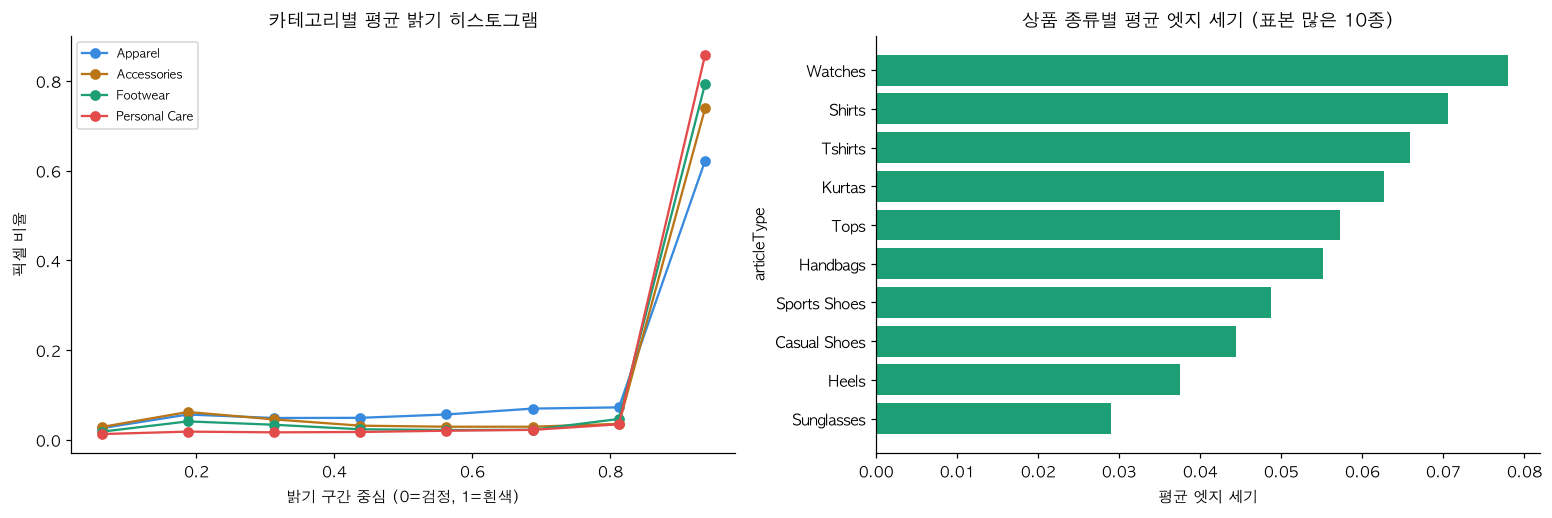

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), layout="constrained")
for c, col in cat_colors.items():
    m = (pr.df["masterCategory"] == c).to_numpy()
    if m.sum() >= 10:
        axes[0].plot(np.arange(8) / 8 + 1 / 16, hist[m].mean(axis=0), marker="o", color=col, label=c)
axes[0].set(title="카테고리별 평균 밝기 히스토그램", xlabel="밝기 구간 중심 (0=검정, 1=흰색)", ylabel="픽셀 비율")
axes[0].legend(fontsize=8)
order = pr.df.groupby("articleType")["edge_strength"].mean()
top_types = pr.df["articleType"].value_counts().index[:10]
order = order[top_types].sort_values()
axes[1].barh(order.index, order.values, color=GREEN)
axes[1].set(title="상품 종류별 평균 엣지 세기 (표본 많은 10종)", xlabel="평균 엣지 세기", ylabel="articleType")
save_figure(fig, "bonus_image_features")
plt.show()

**해석**

- 밝기 히스토그램(8구간)과 엣지 세기를 반복문 없이 배열 연산으로 계산했다. 히스토그램은 구간 번호를 구한 뒤 `np.bincount` 한 번으로 세고, 엣지 세기는 옆·아래 픽셀과의 밝기 차이(`np.diff`)로 구한다.
- 흰 배경 비율(`white_ratio`)은 Personal Care 0.86, Apparel 0.62다. 옷은 화면을 넓게 채우고, 향수·화장품은 작게 찍혀 배경이 많다.
- 평균 엣지 세기는 Apparel 0.06, Personal Care 0.03으로 2배 차이가 난다. 상품 종류로는 시계(Watches)와 셔츠가 높고 선글라스·힐이 낮다. 무늬, 단추, 시곗바늘처럼 **윤곽이 많은 상품일수록 엣지가 세다.**
- 시사점: 평균·표준편차만으로는 구분이 어려운 상품도 히스토그램과 엣지 피처를 더하면 카테고리 분류에 쓸 정보가 늘어난다.

### 보너스 2. 코호트 분석

데이터에 가입일이 없으므로 **고객의 첫 구매 월을 가입 월로 본다.** 재구매율 = 코호트 고객 중 k개월 뒤에도 구매한 고객의 비율.

[저장] outputs/bonus_cohort_heatmap.png


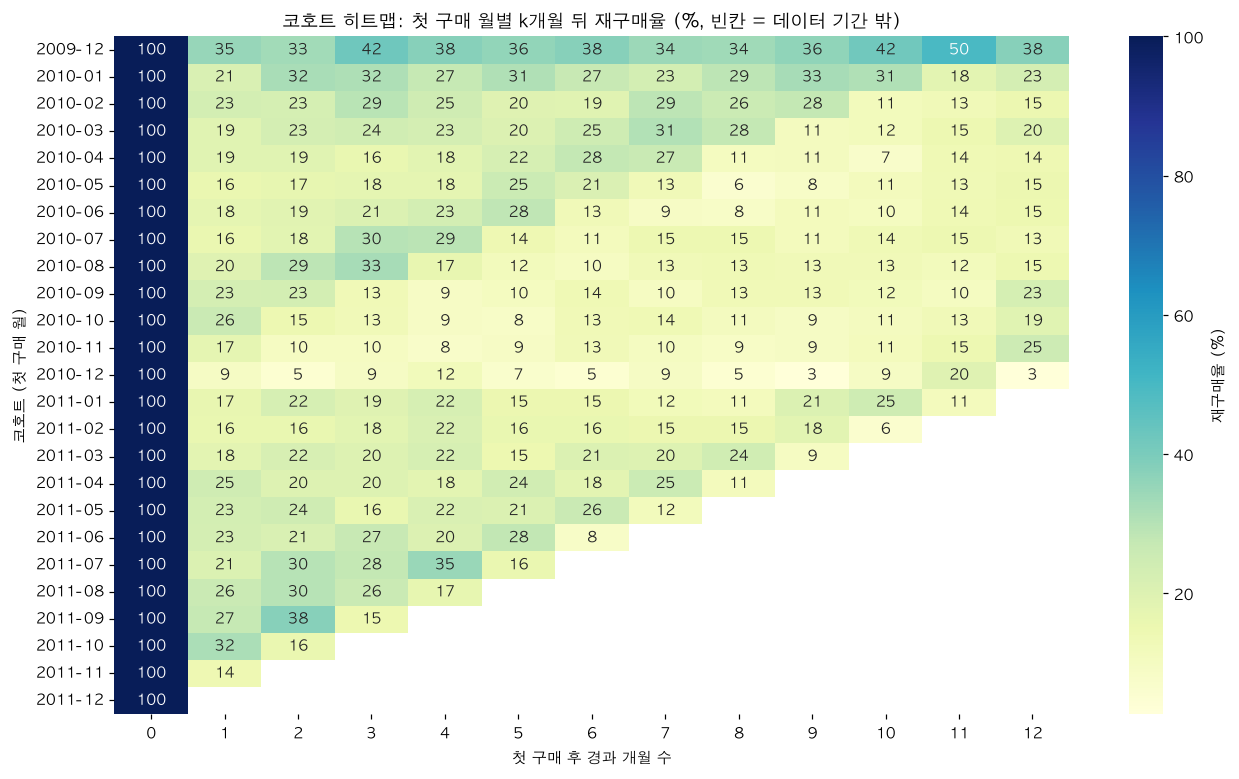

코호트 크기(명): {Period('2009-12', 'M'): 951, Period('2010-01', 'M'): 368, Period('2010-02', 'M'): 375, Period('2010-03', 'M'): 441, Period('2010-04', 'M'): 294, Period('2010-05', 'M'): 255}
1개월 뒤 재구매율 평균 (2009-12 코호트 제외): 20.4%


In [54]:
retention = sa.cohort_retention("Customer ID", "InvoiceDate")
sizes = sa.df.dropna(subset=["Customer ID"]).groupby("Customer ID")["InvoiceDate"].min().dt.to_period("M").value_counts().sort_index()
fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(retention.iloc[:, :13] * 100, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "재구매율 (%)"})
ax.set(title="코호트 히트맵: 첫 구매 월별 k개월 뒤 재구매율 (%, 빈칸 = 데이터 기간 밖)", xlabel="첫 구매 후 경과 개월 수", ylabel="코호트 (첫 구매 월)")
save_figure(fig, "bonus_cohort_heatmap")
plt.show()
print("코호트 크기(명):", sizes.head(6).to_dict())
print("1개월 뒤 재구매율 평균 (2009-12 코호트 제외):", f"{retention.iloc[1:, 1].mean() * 100:.1f}%")

**해석**

- 첫 구매 후 1~6개월 재구매율은 대부분의 코호트에서 15~30% 사이다(2010-01 ~ 2011-06 코호트 평균 19.6%, 2010-12 제외).
- **2009-12 코호트(951명)는 재구매율이 35~50%로 유독 높다.** 데이터가 2009년 12월에 시작하므로, 그 전부터 거래하던 기존 단골이 모두 "2009년 12월 첫 구매"로 잡혔기 때문이다(왼쪽 잘림). 이 코호트는 신규 고객 비교에서 빼야 한다.
- **2010-12 코호트(76명)는 1~6개월 재구매율이 평균 7.9%로 가장 낮다.** 2010-11 코호트(326명)도 11.0%로 낮다. 크리스마스 선물을 사러 한 번 온 고객이 많다는 뜻으로 보인다.
- 오른쪽 아래 빈칸은 0%가 아니라 데이터 기간(2011-12-09까지)이 끝나 아직 관측할 수 없는 칸이다.

### 보너스 3. 인터랙티브 시각화 (Plotly)

이 보너스에 한해 Plotly 사용이 허용된다. 결과는 `outputs/rfm_interactive.html`로 저장한다. 브라우저로 열면 점에 마우스를 올려 고객별 값을 볼 수 있다.

In [55]:
import plotly.express as px

plot_df = rfm.reset_index().rename(columns={"Customer ID": "customer_id"})
fig = px.scatter(plot_df, x="Frequency", y="Monetary", color="segment", size="R", log_x=True, log_y=True,
                 hover_data=["customer_id", "Recency", "Frequency", "Monetary", "R", "F", "M"],
                 category_orders={"segment": seg_order}, color_discrete_map=SEGMENT_COLORS,
                 title="RFM 세그먼트 (점 크기 = R 점수, 마우스를 올리면 고객 정보)",
                 labels={"Frequency": "구매 빈도 (주문 수)", "Monetary": "총 구매 금액 (파운드)"})
out = ROOT / "outputs" / "rfm_interactive.html"
fig.write_html(out, include_plotlyjs="cdn")
print(f"[저장] outputs/{out.name}")

[저장] outputs/rfm_interactive.html


## 11. 처리 기록

In [56]:
for name, a in [("거래", tx), ("판매", sa), ("RFM", ra), ("상품", pr)]:
    print(f"[{name}]")
    for line in a.log:
        print("  ", line)

[거래]
   load_data: 1,067,371행 × 8열
   remove_duplicates: 34,335행 삭제
   exclude_codes(StockCode): 5,801행 제외 (코드 26종)
   handle_missing_values(Description, group_mode, group=StockCode): 3,882칸 채움, 357칸 남음
   handle_missing_values(Description, constant, group=None): 357칸 채움, 0칸 남음
[판매]
   add_text_features(Description) → desc_word_count, desc_char_length
[RFM]
   calculate_rfm: 고객 5,838명, 기준일 2011-12-10, 순 구매 금액 0 이하 14명 제외
[상품]
   load_data: 2,000행 × 11열
   add_image_features: 2,000장 → img_mean, img_std
   add_text_features(productDisplayName) → name_word_count, name_char_length


## 정리

| 단계 | 결과 |
|---|---|
| 데이터 | 거래 1,067,371행 × 8열, 상품 2,000개 × 11열 + 이미지 2,000장. 수치·범주·날짜·텍스트·이미지 5가지 유형 |
| 규칙 위반 | 완전 중복 34,335행(대부분 두 시트가 겹친 2010-12-01~09) 삭제, 비상품 코드 26종 5,801행 제외 |
| 결측치 | 상품명 3,882칸 그룹별(StockCode) 최빈값 대치, 고객 번호 결측 22.7%는 RFM에서 제외 |
| 이상치 | IQR 1.5배 기준 amount 8.19% (z-score는 0.14%만 탐지). 실제 도매 주문이 대부분이라 분포 분석용 사본만 clip |
| 피처 | 이미지 평균·표준편차(벡터 연산), 상품명 단어 수·글자 수, (보너스) 밝기 히스토그램·엣지 세기 |
| 통계 | 거래 금액 중앙값 10.08파운드, 평균 19.58파운드. Frequency–Monetary Spearman 0.86 |
| RFM | 고객 5,838명, 6개 세그먼트. VIP 21.8%가 매출 69.1% |
| 시각화 | 히스토그램, 박스플롯, 막대그래프, 히트맵, 산점도, 라인차트 (outputs/) |
| 보너스 | 이미지 고급 피처, 코호트 히트맵, Plotly 인터랙티브 차트(outputs/rfm_interactive.html) |